# AMC 2026 – Round 1: Strategic Asset Allocation (Group 3)
This notebook builds our Strategic Asset Allocation (SAA), checks it against the risk budget, backtests it, computes the figures of the three report checkpoints and turns the weights into the number of shares to enter in Bloomberg. Section 10 computes the remaining figures of the report and writes every number of the report to `report_figures.json`. The walk-forward test, not used in the report, is kept in the appendix at the end.

### Round 1 rules
- Initial capital: **USD 100 million**
- **Long-only ETFs** tracking broad asset classes · no single stocks · no short positions · no leverage · no leveraged ETFs
- Asset classes, sectors, and geographical areas are freely chosen · **no common benchmark**
- Cash in **USD** is allowed and **earns 0**
- Choose and justify the allocation method: mean-variance, minimum variance, equal weight, risk parity, or another rule
- Target ex-ante volatility: **8% per year**, required to be between **7% and 9%**
- Estimate ex-ante volatility from the **annualized covariance matrix of monthly USD returns**, using the **last 60 months where available**
- Report the **1-month 5% VaR**, both as a **percentage** and in **USD**
- Backtest the SAA with **monthly rebalancing**
- Historical analysis should include **Sharpe Ratio, volatility, maximum drawdown, 5% VaR, and cumulative returns**
- During the actual challenge, performance is ranked by the **realized Sharpe Ratio**, using the **1-month US Treasury bill rate** as the risk-free rate
- The SAA remains unchanged until **Round 2**

### Setup
Libraries, data sources, the parameters of the Round 1 rules and `show`, the helper that formats the numbers of every table (percentages, ratios with 2 decimals, USD amounts with thousands separators).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from pathlib import Path

DATA_FILE  = Path("../code data/AMC_adjusted_prices_final.csv")          # Bloomberg export, adjusted prices
CLOSE_FILE = Path("../code data/AMC_closing_raw.csv")                    # Bloomberg raw closes of Friday 16 October 2026 (section 9)
RF_URL     = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS1MO" # FRED 1-month T-bill, daily, % per year
RF_CACHE   = Path("../code data/DGS1MO.csv")                             # copy of the last FRED download, used if FRED cannot be reached

CAPITAL    = 100_000_000   # USD 100 million
WINDOW     = 60            # months used to estimate the covariance matrix
VOL_MIN    = 0.07          # volatility band of the guidelines
VOL_TARGET = 0.08
VOL_MAX    = 0.09

# Number formats of the tables: 7.39%, 0.55, 3,860,465
PCT, DEC, USD = "{:.2%}", "{:.2f}", "{:,.0f}"

def show(df, fmt=PCT, special=None, axis=0):
    """Table with readable numbers: every number in `fmt`, except the rows (axis=0)
    or columns (axis=1) listed in `special` as {label: format}."""
    num = df.select_dtypes("number").columns
    df = df.copy()
    df[num] = df[num].mask(df[num].abs() < 5e-5, 0)   # optimizer noise (e.g. -1e-12) shown as 0.00%, not -0.00%
    styler = df.style.format(fmt, subset=num, na_rep="")
    if isinstance(df.index, pd.DatetimeIndex):
        styler = styler.format_index("{:%d %b %Y}")      # dates without the time
    for label, f in (special or {}).items():
        subset = pd.IndexSlice[[label], num] if axis == 0 else pd.IndexSlice[:, [label]]
        styler = styler.format(f, subset=subset, na_rep="")
    return styler

## 1. Load the data
- **Bloomberg export** (`AMC_adjusted_prices_final.csv`): daily **adjusted** prices (dividends and splits included) up to 15 October 2026, row 1 = asset class, row 2 = Bloomberg ticker, dates dd/mm/yyyy, `#N/A N/A` before an ETF exists. BCI only listed in 2017, so the file contains the index it tracks, BCOMTR, the return proxy for BCI in sections 2–8
- **Raw closes** (`AMC_closing_raw.csv`): the closes of Friday 16 October 2026 of the nine tickers, BCI US Equity included, the prices Bloomberg uses for the positions entered in PRTU. Section 9 turns the weights into numbers of shares with them
- **Risk-free rate**: FRED series `DGS1MO`, the daily 1-month T-bill rate in % per year (from July 2001), downloaded at each run and saved to `DGS1MO.csv`; if FRED cannot be reached, the notebook uses the last saved copy. Monthly average / 100 / 12 = monthly rate in decimals

In [2]:
# Two header rows (asset class, ticker); Bloomberg error codes become NaN
raw = pd.read_csv(DATA_FILE, header=[0, 1], index_col=0, na_values=["#NOME?", "#N/A N/A"])
raw.index = pd.to_datetime(raw.index, format="%d/%m/%Y")
raw = raw[raw.index.notna()]               # drop the rows without a date at the end of the export

### Baskets
One basket per asset class of row 1 of the file, used by the basket method (section 7). BIL is the cash leg, so it is not in a basket.

In [3]:
# Row 1 names the asset class only above the first ticker of each block: the empty cells ("Unnamed: ...") are filled forward
asset_class = raw.columns.get_level_values(0).to_series().mask(lambda s: s.str.startswith("Unnamed")).ffill()
asset_class = asset_class.str.strip().str.title()                         # "equity" -> "Equity"
asset_class.index = raw.columns.get_level_values(1).str.split().str[0]   # short tickers
asset_class = asset_class.drop("BIL")
BASKETS = {c: list(asset_class.index[asset_class == c]) for c in asset_class.unique()}
BASKETS

{'Equity': ['VTI', 'VEA', 'IEMG'],
 'Bonds': ['BND', 'BNDX', 'TIP'],
 'Commodities': ['GLD', 'BCOMTR']}

### Prices and risk-free rate
Daily prices with the short tickers as column names (last five days shown), and the monthly 1-month T-bill rate.

In [4]:
prices = raw.droplevel(0, axis=1)                          # keep the tickers only
BBG = {c.split()[0]: c for c in prices.columns}            # short ticker -> Bloomberg ticker, e.g. "VTI" -> "VTI US EQUITY"
prices = prices.rename(columns=lambda c: c.split()[0])
BBG_TRADE = {**BBG, "BCOMTR": "BCI US EQUITY"}             # tickers we hold: BCI, the ETF that tracks the BCOMTR index
NAMES = {"VTI":    "Vanguard Total Stock Market ETF",
         "VEA":    "Vanguard FTSE Developed Markets ETF",
         "IEMG":   "iShares Core MSCI Emerging Markets ETF",
         "BND":    "Vanguard Total Bond Market ETF",
         "BNDX":   "Vanguard Total International Bond ETF",
         "TIP":    "iShares TIPS Bond ETF",
         "GLD":    "SPDR Gold Shares",
         "BCOMTR": "abrdn Bloomberg All Commodity Strategy K-1 Free ETF",
         "BIL":    "SPDR Bloomberg 1-3 Month T-Bill ETF"}

ASSETS = list(prices.columns.drop("BIL"))   # risky ETFs, the inputs of the optimizer
n = len(ASSETS)                             # BIL, the cash leg, gets 1 - sum of the risky weights

# 1-month T-bill: average daily rate of each month (days without a rate skipped), from % per year to a decimal per month
try:
    tbill = pd.read_csv(RF_URL, index_col=0, parse_dates=True).iloc[:, 0]
    tbill.to_csv(RF_CACHE)                                   # keep a copy next to the prices
except Exception as e:                                       # FRED cannot be reached: last saved copy
    tbill = pd.read_csv(RF_CACHE, index_col=0, parse_dates=True).iloc[:, 0]
    print(f"FRED download failed ({e}): using {RF_CACHE.name}, data up to {tbill.index[-1]:%d %b %Y}")
rf_m  = pd.to_numeric(tbill, errors="coerce").resample("ME").mean() / 100 / 12
show(prices.tail(), "{:,.2f}")

,VTI,VEA,IEMG,BND,BNDX,TIP,GLD,BCOMTR,BIL
09 Oct 2026,381.57,69.95,80.63,70.25,46.97,104.50,382.15,374.67,91.50
12 Oct 2026,381.32,70.06,80.22,70.33,47.01,104.56,381.67,375.57,91.52
13 Oct 2026,376.88,69.30,78.64,70.40,47.05,104.82,375.99,373.53,91.52
14 Oct 2026,378.42,69.66,78.09,70.81,47.21,105.29,382.71,373.11,91.54
15 Oct 2026,378.42,69.66,78.09,70.81,47.21,105.29,382.71,373.24,91.54


## 2. Monthly returns
Month-end prices, then simple monthly returns $R_t = P_t / P_{t-1} - 1$ (last five months shown). BIL is taken out of `R` and kept as `R_bil`, the return of the cash leg.

In [5]:
prices = prices.ffill().dropna()          # holidays: last available price; start when every ETF exists

monthly = prices.resample("ME").last()    # last price of each month
if prices.index[-1] < prices.index[-1] + pd.offsets.BMonthEnd(0):
    monthly = monthly.iloc[:-1]           # drop the current month if it is not complete

R = monthly.pct_change().dropna()         # monthly simple returns
R_bil = R.pop("BIL")                      # cash leg, removed from R: R = risky ETFs only

rf = rf_m.reindex(R.index).ffill()        # risk-free rate on the dates of R
show(R.tail())

,VTI,VEA,IEMG,BND,BNDX,TIP,GLD,BCOMTR
31 May 2026,5.10%,4.58%,8.30%,0.09%,0.53%,-0.08%,-2.82%,-2.22%
30 Jun 2026,-0.82%,-1.59%,-4.58%,0.17%,0.56%,-0.69%,-9.89%,-9.58%
31 Jul 2026,1.24%,0.97%,-3.13%,-0.90%,-0.64%,-0.49%,0.30%,6.35%
31 Aug 2026,0.36%,1.51%,4.25%,-0.15%,-0.94%,-0.05%,6.74%,10.01%
30 Sep 2026,0.25%,-2.39%,-0.26%,-2.02%,-0.77%,-2.34%,-3.53%,-0.37%


## 3. Descriptive analysis
Annualized and cumulative return, annualized volatility, Sharpe and Sortino Ratios (excess return over the T-bill; Sortino divides by the downside deviation only) and maximum drawdown of each ETF over the full sample, and the growth of USD 1. `perf` and `perf_table` are reused for every backtest of section 8.

,Ann. return,Cum. return,Ann. vol,Sharpe,Sortino,Max drawdown
VTI,14.34%,461.49%,15.70%,0.79,1.22,-25.09%
VEA,9.22%,187.62%,15.58%,0.47,0.70,-27.69%
IEMG,8.32%,146.52%,17.20%,0.38,0.55,-34.00%
BND,1.90%,26.69%,4.87%,0.01,0.01,-17.16%
BNDX,2.36%,35.09%,4.19%,0.12,0.16,-14.75%
TIP,2.16%,31.06%,4.85%,0.06,0.08,-12.94%
GLD,9.93%,215.99%,15.70%,0.51,0.86,-24.63%
BCOMTR,3.93%,45.94%,14.60%,0.14,0.20,-53.14%


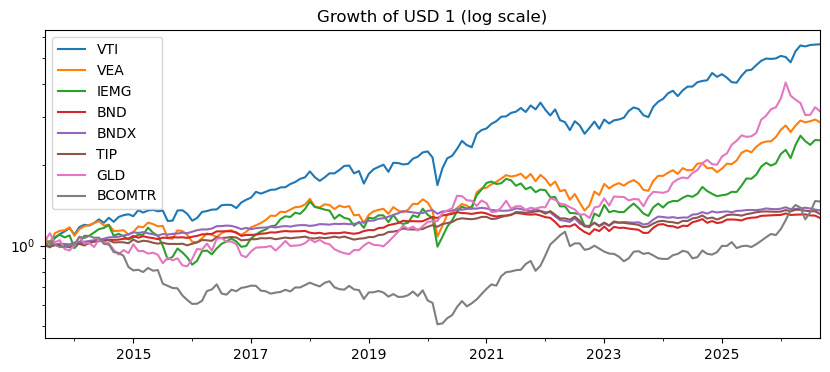

In [6]:
def perf(r, rf):
    wealth = (1 + r).cumprod()                                  # value of USD 1 invested
    excess = r - rf
    downside = np.sqrt((excess.clip(upper=0) ** 2).mean())      # downside deviation of the excess return
    return pd.Series({
        "Ann. return":  r.mean() * 12,
        "Cum. return":  wealth.iloc[-1] - 1,
        "Ann. vol":     r.std() * np.sqrt(12),
        "Sharpe":       excess.mean() / r.std() * np.sqrt(12),
        "Sortino":      excess.mean() / downside * np.sqrt(12),
        "Max drawdown": (wealth / wealth.cummax() - 1).min(),   # cummax = running peak
    })

def perf_table(returns, rf):
    """perf of each column of `returns`, one row per column."""
    table = pd.DataFrame({c: perf(returns[c], rf) for c in returns.columns}).T
    return show(table, special={"Sharpe": DEC, "Sortino": DEC}, axis=1)

display(perf_table(R, rf))

(1 + R).cumprod().plot(figsize=(10, 4), logy=True, title="Growth of USD 1 (log scale)")
plt.show()

## 4. Inputs: the last 60 months
The inputs of the allocation, estimated on the last 60 complete months as the guidelines require: annualized covariance matrix `V`, volatilities, correlations, and expected excess returns `mu` (average monthly return minus the T-bill, × 12). Our SAA uses only `V`; `mu` is used by Max Sharpe and MVO. Sources: Bloomberg adjusted prices (BCOMTR index as the proxy for BCI) and the FRED 1-month T-bill.

In [7]:
est = R.iloc[-WINDOW:]                                      # last 60 months
V = est.cov() * 12                                          # annualized covariance matrix
vol = pd.Series(np.sqrt(np.diag(V)), index=ASSETS)          # annualized volatilities
corr = V / np.outer(vol, vol)                               # correlation matrix
mu = est.sub(rf.iloc[-WINDOW:], axis=0).mean() * 12         # annualized expected excess returns

print(f"Estimation window: {est.index[0]:%b %Y} - {est.index[-1]:%b %Y} ({est.count().min()} monthly returns for every ETF)")
display(show(pd.DataFrame({"Vol": vol, "Expected excess return": mu})))
show(corr, DEC).background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

Estimation window: Oct 2021 - Sep 2026 (60 monthly returns for every ETF)


,Vol,Expected excess return
VTI,15.24%,8.97%
VEA,15.67%,7.02%
IEMG,16.28%,5.86%
BND,6.76%,-4.25%
BNDX,5.57%,-3.74%
TIP,6.00%,-3.87%
GLD,17.08%,14.58%
BCOMTR,15.36%,8.10%


,VTI,VEA,IEMG,BND,BNDX,TIP,GLD,BCOMTR
VTI,1.00,0.82,0.72,0.50,0.53,0.53,0.14,0.09
VEA,0.82,1.00,0.81,0.64,0.58,0.62,0.42,0.20
IEMG,0.72,0.81,1.00,0.56,0.47,0.53,0.44,0.24
BND,0.50,0.64,0.56,1.00,0.89,0.90,0.46,-0.06
BNDX,0.53,0.58,0.47,0.89,1.00,0.85,0.41,-0.13
TIP,0.53,0.62,0.53,0.90,0.85,1.00,0.47,0.12
GLD,0.14,0.42,0.44,0.46,0.41,0.47,1.00,0.31
BCOMTR,0.09,0.20,0.24,-0.06,-0.13,0.12,0.31,1.00


## 5. Risk tools
Ex-ante volatility $\sqrt{w^\top V w}$, risk contributions (share of the portfolio variance due to each ETF, summing to 1) and the 1-month 5% VaR under normality, $1.645 \, \sigma / \sqrt{12}$, as a fraction of capital.

In [8]:
def port_vol(w, V):
    w = np.asarray(w)
    return np.sqrt(w @ V @ w)                 # ex-ante annual volatility

def risk_contrib(w, V):
    w = np.asarray(w)
    return w * (V @ w) / (w @ V @ w)          # share of the variance due to each ETF (sums to 1)

def var_normal(vol_annual):
    return 1.645 * vol_annual / np.sqrt(12)   # 1-month 5% VaR, fraction of capital

## 6. Simple rules
Equal weight and risk parity (weights ∝ 1/σ) on the risky ETFs, fully invested. They are the **benchmarks required by Checkpoint 2, not candidates** for our SAA: they allocate by ETF, so the number of ETFs in each asset class decides the allocation (three bond ETFs out of eight take 3/8 of the capital under equal weight), whatever the role of the asset class. The basket method of section 7 fixes this by setting the risk of each asset class.

In [9]:
def w_equal(V):
    return np.ones(len(V)) / len(V)        # 1/N each

def w_riskparity(V):
    inv_vol = 1 / np.sqrt(np.diag(V))      # 1 / sigma_i
    return inv_vol / inv_vol.sum()         # weights sum to 1

## 7. Constrained optimizations under the AMC rules
The simple rules ignore the 7–9% volatility band, so the other allocations are solved numerically with `scipy` (`SLSQP`, starting from equal weights).

**Constraints common to all the problems** (`amc_constraints`):

$$
0 \le w_i \le 1 \;\;\text{(long-only)}, \qquad
\sum_{i=1}^{N} w_i \le 1 \;\;\text{(no leverage, } w_{BIL} = 1 - \textstyle\sum_i w_i \text{)}, \qquad
7\% \le \sqrt{w^\top V w} \le 9\%
$$

| Portfolio | Objective | Extra constraint |
|---|---|---|
| Minimum variance | $\min_w \; \sqrt{w^\top V w}$ | – |
| Maximum Sharpe | $\max_w \; \dfrac{w^\top \mu^e}{\sqrt{w^\top V w}}$ | – |
| Risk parity (ERC) | $\min_w \; \sum_i \left( \dfrac{w_i (Vw)_i}{w^\top V w} - \dfrac{1}{N} \right)^2$ | – |
| Mean-variance @ 8% | $\max_w \; w^\top \mu^e$ | $\sqrt{w^\top V w} = 8\%$ |
| Maximum diversification (MDP) | $\max_w \; \dfrac{w^\top \sigma}{\sqrt{w^\top V w}}$ | – |
| Basket method | $\min_{w_B} \; \sum_k \left( \dfrac{w_{B,k} (V_B w_B)_k}{w_B^\top V_B w_B} - b_k \right)^2$ | ERC within each basket |

**Basket method.** One basket per asset class (Equity, Bonds, Commodities). Within each basket the weights are ERC: each ETF carries the same share of the basket's variance. Across the baskets, risk budgeting on the covariance matrix $V_B$ of the basket returns: budget $b_E$ to equity and $(1-b_E)/2$ to each of the other two baskets, under the same AMC constraints. Four equity budgets are compared.

`scipy` only minimizes, so Max Sharpe, MVO and MDP minimize the negative of their objective.

**Candidates, benchmarks and diagnostics** (`GROUPS`, 7a). Only the four basket allocations were candidates for our SAA. Equal weight and risk parity 1/vol (section 6) are the benchmarks of Checkpoint 2. The other five were never candidates: they are diagnostics, kept because they show what each rule does with our universe:
- Max Sharpe and MVO @ 8% show the estimation-error problem: they use the expected returns and load on the winners of the last five years
- Min var stops at the 7% floor of the band, with a solution that is not unique
- ERC on the 8 ETFs and MDP allocate by ETF, so they are asset-class agnostic, like the benchmarks

In [10]:
def amc_constraints(V):
    """No leverage (rest in BIL) and vol between 7% and 9%; long-only is set by the bounds in solve."""
    return [
        {"type": "ineq", "fun": lambda w: 1 - w.sum()},                 # sum of the weights <= 1, rest in BIL
        {"type": "ineq", "fun": lambda w: port_vol(w, V) - VOL_MIN},    # vol >= 7%
        {"type": "ineq", "fun": lambda w: VOL_MAX - port_vol(w, V)},    # vol <= 9%
    ]

amc = amc_constraints(V.values)

def solve(objective, constraints=amc, size=n):
    res = minimize(objective,
                   x0=np.ones(size) / size,
                   method="SLSQP",
                   bounds=[(0, 1)] * size,   # long-only
                   constraints=constraints)
    return res.x

# 1. Minimum variance
w_minvar = solve(lambda w: port_vol(w, V.values))

# 2. Maximum Sharpe
w_maxsr = solve(lambda w: -(w @ mu.values) / port_vol(w, V.values))

# 3. Equal risk contribution
w_erc = solve(lambda w: ((risk_contrib(w, V.values) - 1 / n) ** 2).sum())

# 4. Mean-variance at exactly 8%
mvo_constraints = amc + [{"type": "eq", "fun": lambda w: port_vol(w, V.values) - VOL_TARGET}]
w_mvo = solve(lambda w: -(w @ mu.values), mvo_constraints)

# 5. Maximum diversification
w_mdp = solve(lambda w: -(w @ vol.values) / port_vol(w, V.values))

# 6. Basket method, one allocation per equity risk budget b_E
EQUITY_BUDGETS = {"Basket 1/3": 1/3, "Basket 50/25/25": 0.50, "Basket 60/20/20": 0.60, "Basket 70/15/15": 0.70}

def w_erc_within(V):
    """ERC weights inside one basket, fully invested."""
    return solve(lambda w: ((risk_contrib(w, V) - 1 / len(V)) ** 2).sum(),
                 [{"type": "eq", "fun": lambda w: w.sum() - 1}], size=len(V))

def w_basket(V, R_est, b_E):
    V = np.asarray(V)
    idx = {b: [ASSETS.index(t) for t in tickers] for b, tickers in BASKETS.items()}   # positions of each basket in ASSETS
    within = {b: w_erc_within(V[np.ix_(i, i)]) for b, i in idx.items()}                 # ERC within each basket
    R_b = pd.DataFrame({b: R_est.iloc[:, i] @ within[b] for b, i in idx.items()})     # monthly return of each basket
    V_b = R_b.cov().values * 12                                                         # covariance matrix of the baskets
    budget = np.array([b_E if b == "Equity" else (1 - b_E) / (len(BASKETS) - 1) for b in BASKETS])
    w_b = solve(lambda x: ((risk_contrib(x, V_b) - budget) ** 2).sum(),
                amc_constraints(V_b), size=len(BASKETS))                                # weight of each basket
    w = np.zeros(n)
    for k, (b, i) in enumerate(idx.items()):
        w[i] = w_b[k] * within[b]                                                       # basket weight x weight within
    return w

w_baskets = {name: w_basket(V, est, b_E) for name, b_E in EQUITY_BUDGETS.items()}

### 7a. Comparison of the allocations
Weights, cash in BIL, ex-ante volatility and Sharpe Ratio, and 1-month 5% VaR of every allocation, on the last 60 months. The allocations are grouped as candidates (the four baskets), benchmarks of Checkpoint 2 (EW, RP 1/vol) and diagnostics (the other five): `GROUPS` orders and labels every table that follows.

In [11]:
# The eleven allocations in three groups: only the four baskets were candidates for our SAA (section 7)
GROUPS = {"Candidates":       ["Basket 1/3", "Basket 50/25/25", "Basket 60/20/20", "Basket 70/15/15"],
          "Benchmarks (CP2)": ["EW", "RP 1/vol"],
          "Diagnostics":      ["Min var", "Max Sharpe", "RP (ERC)", "MVO @ 8%", "MDP"]}
GROUP = {c: g for g, cols in GROUPS.items() for c in cols}           # allocation -> its group

def grouped(df, axis=0):
    """df with its allocations (rows if axis=0, columns if axis=1) labelled by group: a two-level index (group, allocation)."""
    labels = df.index if axis == 0 else df.columns
    return df.set_axis(pd.MultiIndex.from_tuples([(GROUP[c], c) for c in labels]), axis=axis)

W = pd.DataFrame({"EW": w_equal(V), "RP 1/vol": w_riskparity(V), "Min var": w_minvar,
                  "Max Sharpe": w_maxsr, "RP (ERC)": w_erc, "MVO @ 8%": w_mvo, "MDP": w_mdp, **w_baskets}, index=ASSETS)
assert sorted(c for cols in GROUPS.values() for c in cols) == sorted(W.columns), "each allocation must be in exactly one group"
W = W[list(GROUP)]                                                   # columns ordered by group
summary = pd.DataFrame({c: {"BIL": 1 - W[c].sum(),
                            "Ex-ante vol": port_vol(W[c], V.values),
                            "Ex-ante Sharpe": (W[c] @ mu) / port_vol(W[c], V.values),
                            "VaR 5% 1m": var_normal(port_vol(W[c], V.values)),
                            "VaR USD": var_normal(port_vol(W[c], V.values)) * CAPITAL} for c in W})

outside = [c for c in W if not VOL_MIN <= round(summary.loc["Ex-ante vol", c], 4) <= VOL_MAX]
print("Allocations outside the 7-9% band:", ", ".join(outside) if outside else "none")
show(grouped(pd.concat([W, summary]), axis=1), special={"Ex-ante Sharpe": DEC, "VaR USD": USD})

Allocations outside the 7-9% band: none


### 7b. Our SAA
**We allocate risk, not capital.** Each asset class has a distinct role. Equity is the growth engine: it carries the equity risk premium, which rests on economic growth and corporate earnings. Bonds and commodities are the brakes: nominal bonds perform when growth and inflation fall, commodities (and TIPS) when inflation rises, so together they protect the portfolio in the regimes where equity suffers.

**The rules came before the choice.** Equity gets the largest share of the risk, but at most 70%; bonds + commodities at least 30%, split equally. Within these rules we tested four budgets (equity 1/3, 50%, 60%, 70%) and chose **50/25/25** because it is the closest to the 8% volatility target: the effect of a risk budget on the volatility is hard to anticipate ex ante. The backtests only confirmed that the four budgets have practically the same hold-out Sharpe Ratio (the range is printed in 8b). For reference, a 60/40 portfolio has about 90% of its risk in equity (Class 3): even the 70% budget is more balanced.

Our SAA is the portfolio of the checkpoints and of section 9. Below, the rules checked on the four candidates: the risk of each basket is the sum of the risk contributions of its ETFs.

In [12]:
SAA = "Basket 50/25/25"   # our SAA: a column of W

def by_basket(x):
    """Sum of x (one value per ETF, in the order of ASSETS) over the ETFs of each basket."""
    x = pd.Series(np.asarray(x), index=ASSETS)
    return pd.Series({b: x[tickers].sum() for b, tickers in BASKETS.items()})

# The rules of the risk budget, checked on the four candidates (0.1 pp of tolerance for the optimizer)
basket_risk = pd.DataFrame({c: by_basket(risk_contrib(W[c], V.values)) for c in GROUPS["Candidates"]})
assert (basket_risk.loc["Equity"] <= 0.70 + 0.001).all(), "equity above 70% of the risk"
assert (basket_risk.loc[["Bonds", "Commodities"]].sum() >= 0.30 - 0.001).all(), "bonds + commodities below 30% of the risk"
show(basket_risk)

,Basket 1/3,Basket 50/25/25,Basket 60/20/20,Basket 70/15/15
Equity,33.31%,49.99%,60.01%,69.97%
Bonds,33.34%,25.01%,19.97%,15.06%
Commodities,33.35%,25.00%,20.02%,14.97%


## 8. Backtest with monthly rebalancing
Each allocation of `W` is held with fixed weights, rebalanced every month; the rest of the capital is in BIL. No transaction costs, since the guidelines do not mention them. Three tests, each with its question and its limit:
- **Full sample** (this section): our weights on all 159 months. **Reference only**: the last 60 months are the estimation window of the weights, so they are in-sample
- **Hold-out** (8b): our weights on the 99 months before the estimation window. The test we rely on, because it tests the mix we hold until Round 2; its limit is look-ahead
- **Split** (8c): each rule estimated once on the first 60 months and held fixed on the following 99, as our SAA is held fixed. No look-ahead, but it tests the method, not our weights

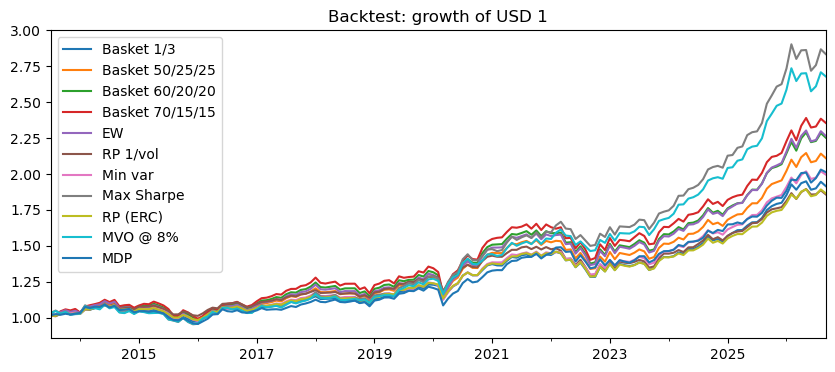

In [13]:
def backtest(w, R):
    """Monthly returns of fixed weights w, rebalanced every month: w'R_t + (1 - sum w) R_BIL,t."""
    w = np.asarray(w)
    return pd.Series(R.values @ w + (1 - w.sum()) * R_bil[R.index].values, index=R.index)

bt = pd.DataFrame({c: backtest(W[c], R) for c in W.columns})   # one column per allocation
display(perf_table(grouped(bt, axis=1), rf))

(1 + bt).cumprod().plot(figsize=(10, 4), title="Backtest: growth of USD 1")
plt.show()

### 8b. Hold-out test: the months before the estimation window
**What it tests:** our actual weights, the weights of `W` estimated on the last 60 months, on the 99 months before the estimation window, which the optimizer never saw.
- No in-sample fitting: Max Sharpe and MVO get no advantage from being fitted on the test data
- **Limit, look-ahead:** weights estimated on 2021–2026 are applied to 2013–2021, which no investor could have done. The test shows whether these weights hold up in another market regime
- **Why we rely on it:** it tests the mix we hold until Round 2, not the method (that is the split test, 8c) and not what re-optimizing would give

Estimation window: Oct 2021 - Sep 2026 (60 months, in-sample)
Hold-out sample:   Jul 2013 - Sep 2021 (99 months, out-of-sample)


Hold-out Sharpe Ratio of the four candidates: 0.65-0.66


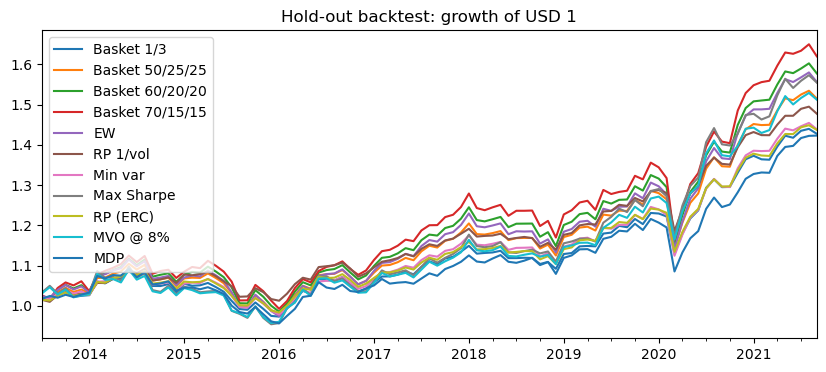

In [14]:
holdout = R.index < est.index[0]          # the months before the estimation window
R_out, rf_out = R[holdout], rf[holdout]
print(f"Estimation window: {est.index[0]:%b %Y} - {est.index[-1]:%b %Y} ({len(est)} months, in-sample)")
print(f"Hold-out sample:   {R_out.index[0]:%b %Y} - {R_out.index[-1]:%b %Y} ({len(R_out)} months, out-of-sample)")

bt_out = pd.DataFrame({c: backtest(W[c], R_out) for c in W.columns})
display(perf_table(grouped(bt_out, axis=1), rf_out))
sr_cand = pd.Series({c: perf(bt_out[c], rf_out)["Sharpe"] for c in GROUPS["Candidates"]})
print(f"Hold-out Sharpe Ratio of the four candidates: {sr_cand.min():.2f}-{sr_cand.max():.2f}")

(1 + bt_out).cumprod().plot(figsize=(10, 4), title="Hold-out backtest: growth of USD 1")
plt.show()

### 8c. Split test: estimate on the first 60 months, test on the months after
**What it tests:** the rules of sections 6–7 estimated once, with `V` and `mu` of the first 60 months only, and these fixed weights held, rebalanced monthly, on all the following months, as our SAA is held fixed until Round 2.
- No look-ahead: an investor could have built these weights at the end of the estimation window
- **Limit:** it tests the method, not our weights: the weights `W_first` differ from `W`
- A single split: the results depend on that one window (a calm window underestimates the later volatility); the ETF list was chosen today with hindsight

Estimation window: Jul 2013 - Jun 2018 (60 months, in-sample)
Test sample:       Jul 2018 - Sep 2026 (99 months, out-of-sample)


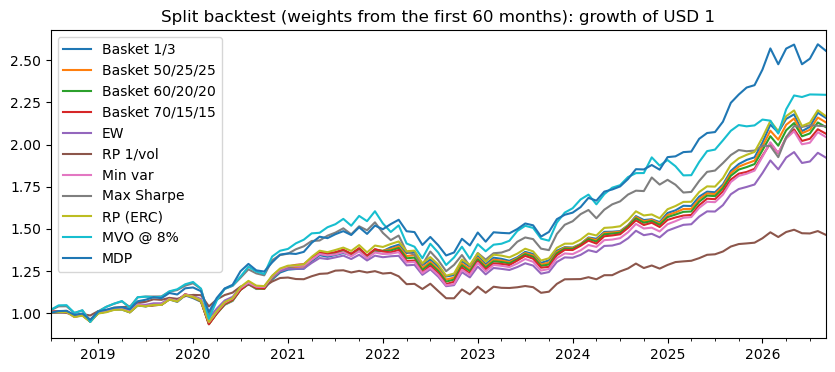

In [15]:
def allocations(V_t, mu_t, est_t):
    """The allocations of sections 6-7, rebuilt on one estimation window (returns est_t, V_t, mu_t). Also used by the walk-forward test (appendix)."""
    cons = amc_constraints(V_t)
    mvo_cons = cons + [{"type": "eq", "fun": lambda w: port_vol(w, V_t) - VOL_TARGET}]
    return {"EW":         w_equal(V_t),
            "RP 1/vol":   w_riskparity(V_t),
            "Min var":    solve(lambda w: port_vol(w, V_t), cons),
            "Max Sharpe": solve(lambda w: -(w @ mu_t) / port_vol(w, V_t), cons),
            "RP (ERC)":   solve(lambda w: ((risk_contrib(w, V_t) - 1 / n) ** 2).sum(), cons),
            "MVO @ 8%":   solve(lambda w: -(w @ mu_t), mvo_cons),
            "MDP":        solve(lambda w: -(w @ np.sqrt(np.diag(V_t))) / port_vol(w, V_t), cons),
            **{name: w_basket(V_t, est_t, b_E) for name, b_E in EQUITY_BUDGETS.items()}}

est_first = R.iloc[:WINDOW]                                               # first 60 months
V_first   = (est_first.cov() * 12).values
mu_first  = (est_first.sub(rf.iloc[:WINDOW], axis=0).mean() * 12).values
W_first   = pd.DataFrame(allocations(V_first, mu_first, est_first), index=ASSETS)[W.columns]

R_test, rf_test = R.iloc[WINDOW:], rf.iloc[WINDOW:]                       # all the months after
print(f"Estimation window: {est_first.index[0]:%b %Y} - {est_first.index[-1]:%b %Y} ({len(est_first)} months, in-sample)")
print(f"Test sample:       {R_test.index[0]:%b %Y} - {R_test.index[-1]:%b %Y} ({len(R_test)} months, out-of-sample)")

# Weights from the first 60 months, with BIL and the ex-ante vol (to compare with the realized "Ann. vol" below)
first_summary = pd.DataFrame({c: {"BIL": 1 - W_first[c].sum(), "Ex-ante vol": port_vol(W_first[c], V_first)} for c in W_first})
display(show(grouped(pd.concat([W_first, first_summary]), axis=1)))

bt_first = pd.DataFrame({c: backtest(W_first[c], R_test) for c in W_first.columns})
display(perf_table(grouped(bt_first, axis=1), rf_test))

(1 + bt_first).cumprod().plot(figsize=(10, 4), title="Split backtest (weights from the first 60 months): growth of USD 1")
plt.show()

### 8e. Backtest summary
The two tables of the report on the backtests:
- **Our SAA in the three tests** (report Table 8): return, volatility, Sharpe Ratio with its t-statistic (Sharpe × √years), Sortino Ratio, maximum drawdown and 1-month 5% VaR (normal, 1.645 × realized monthly volatility, as the ex-ante VaR). The split column holds the weights of the rule estimated on the first 60 months (`W_first`), not ours
- **The eleven allocations by group** (report Table 10): Sharpe Ratio and realized (ex-post) volatility in the full sample and in the hold-out. The Sharpe Ratios of the eleven allocations in the split test remain in 8c

The tests cover different periods: compare the ranking of the allocations within a column rather than the levels across columns.

In [16]:
print(f"Full sample:   {R.index[0]:%b %Y} - {R.index[-1]:%b %Y}  weights from the last 60 months, all months (the last 60 are in-sample)")
print(f"Hold-out (8b): {R_out.index[0]:%b %Y} - {R_out.index[-1]:%b %Y}  weights from the last 60 months, the months before them")
print(f"Split (8c):    {R_test.index[0]:%b %Y} - {R_test.index[-1]:%b %Y}  weights from the first 60 months, the months after them")

# a. Our SAA in the three tests (report Table 8)
def saa_summary(r, rf_s):
    p = perf(r, rf_s)
    return pd.Series({"Months":       len(r),
                      "Ann. return":  p["Ann. return"],
                      "Cum. return":  p["Cum. return"],
                      "Ann. vol":     p["Ann. vol"],
                      "Sharpe":       p["Sharpe"],
                      "t-stat":       p["Sharpe"] * np.sqrt(len(r) / 12),   # = mean excess return / (vol / sqrt(T))
                      "Sortino":      p["Sortino"],
                      "Max drawdown": p["Max drawdown"],
                      "VaR 5% 1m":    var_normal(p["Ann. vol"])})

table8 = pd.DataFrame({"Full sample":   saa_summary(bt[SAA], rf),
                       "Hold-out (8b)": saa_summary(bt_out[SAA], rf_out),
                       "Split (8c)":    saa_summary(bt_first[SAA], rf_test)})
display(show(table8, special={"Months": USD, "Sharpe": DEC, "t-stat": DEC, "Sortino": DEC}))

# b. The eleven allocations by group (report Table 10): Sharpe Ratio and ex-post volatility, full sample and hold-out
table10 = pd.concat({"Full sample":   pd.DataFrame({c: perf(bt[c], rf)[["Sharpe", "Ann. vol"]] for c in W.columns}).T,
                     "Hold-out (8b)": pd.DataFrame({c: perf(bt_out[c], rf_out)[["Sharpe", "Ann. vol"]] for c in W.columns}).T},
                    axis=1)
show(grouped(table10), special={("Full sample", "Sharpe"): DEC, ("Hold-out (8b)", "Sharpe"): DEC}, axis=1)

Full sample:   Jul 2013 - Sep 2026  weights from the last 60 months, all months (the last 60 are in-sample)
Hold-out (8b): Jul 2013 - Sep 2021  weights from the last 60 months, the months before them
Split (8c):    Jul 2018 - Sep 2026  weights from the first 60 months, the months after them


,Full sample,Hold-out (8b),Split (8c)
Months,159,99,99
Ann. return,5.92%,5.28%,9.75%
Cum. return,111.10%,51.48%,113.19%
Ann. vol,7.39%,6.94%,10.35%
Sharpe,0.55,0.66,0.68
t-stat,2.00,1.91,1.94
Sortino,0.83,1.01,1.01
Max drawdown,-13.04%,-11.24%,-15.57%
VaR 5% 1m,3.51%,3.30%,4.92%


## Checkpoints of the Round 1 report
The figures asked by the three checkpoints, for our SAA, in the order of the report. The choices of the team (maximum acceptable drawdown, discount, number of variations) are set at the top of each cell; their reasons are written in the report. BCOMTR is the return proxy for **BCI US Equity**, the ETF we hold.

### CP1. Investment policy
Universe; objective and risk budget (ex-ante volatility, 1-month 5% VaR, maximum acceptable drawdown); weight and risk contribution of each position, and whether a single position carries more than half of the risk; capital and risk of each basket, and the regional split of the equity capital.

In [17]:
MAX_DD = -0.15   # maximum acceptable drawdown, the team's choice (report, Checkpoint 1)

# Universe: name, ticker held and asset class of each position
display(show(pd.DataFrame({"Name": NAMES,
                      "Bloomberg ticker": BBG_TRADE,
                      "Asset class": pd.concat([asset_class, pd.Series({"BIL": "Cash"})])}).loc[ASSETS + ["BIL"]]))

# Objective and risk budget
vol_saa = port_vol(W[SAA], V.values)
print(f"Objective: Sharpe Ratio | vol target {VOL_TARGET:.0%} (range {VOL_MIN:.0%}-{VOL_MAX:.0%}) | ex-ante vol {vol_saa:.2%} | "
      f"1-month 5% VaR {var_normal(vol_saa):.2%} = USD {var_normal(vol_saa) * CAPITAL:,.0f}")
print(f"Maximum acceptable drawdown: {MAX_DD:.0%} | worst drawdown of our weights in the full sample (section 8): "
      f"{perf(bt[SAA], rf)['Max drawdown']:.2%}")

# Weight and risk contribution of each position (BIL has zero vol, so zero risk)
cp1 = pd.DataFrame({"Weight": W[SAA], "%RC": risk_contrib(W[SAA], V.values)})
cp1.loc["BIL"] = [1 - W[SAA].sum(), 0]
top = cp1.loc[ASSETS, "%RC"]
print(f"Largest risk contribution: {top.idxmax()} {top.max():.1%} ({'above' if top.max() > 0.5 else 'below'} half of the risk)")
cp1.loc["Total"] = cp1.sum()
display(show(cp1))

# Capital and risk of each basket (BIL is the cash leg: no risk), and the regional split of the equity capital
cp1_baskets = pd.DataFrame({"Capital": by_basket(W[SAA]), "Risk": by_basket(risk_contrib(W[SAA], V.values))})
cp1_baskets.loc["BIL"] = [1 - W[SAA].sum(), 0]
eq = W[SAA][BASKETS["Equity"]]
print("Regional split of the equity capital: " + " / ".join(f"{t} {x:.1%}" for t, x in (eq / eq.sum()).items()))
show(cp1_baskets)

,Name,Bloomberg ticker,Asset class
VTI,Vanguard Total Stock Market ETF,VTI US EQUITY,Equity
VEA,Vanguard FTSE Developed Markets ETF,VEA US EQUITY,Equity
IEMG,iShares Core MSCI Emerging Markets ETF,IEMG US EQUITY,Equity
BND,Vanguard Total Bond Market ETF,BND US EQUITY,Bonds
BNDX,Vanguard Total International Bond ETF,BNDX US EQUITY,Bonds
TIP,iShares TIPS Bond ETF,TIP US EQUITY,Bonds
GLD,SPDR Gold Shares,GLD US EQUITY,Commodities
BCOMTR,abrdn Bloomberg All Commodity Strategy K-1 Free ETF,BCI US EQUITY,Commodities
BIL,SPDR Bloomberg 1-3 Month T-Bill ETF,BIL US EQUITY,Cash


Objective: Sharpe Ratio | vol target 8% (range 7%-9%) | ex-ante vol 8.13% | 1-month 5% VaR 3.86% = USD 3,860,465
Maximum acceptable drawdown: -15% | worst drawdown of our weights in the full sample (section 8): -13.04%
Largest risk contribution: VEA 17.4% (below half of the risk)


,Weight,%RC
VTI,10.90%,15.21%
VEA,10.24%,17.42%
IEMG,10.23%,17.36%
BND,13.33%,8.34%
BNDX,16.48%,7.83%
TIP,15.26%,8.84%
GLD,11.15%,15.49%
BCOMTR,12.40%,9.51%
BIL,0.01%,0.00%
Total,100.00%,100.00%


Regional split of the equity capital: VTI 34.7% / VEA 32.6% / IEMG 32.6%


,Capital,Risk
Equity,31.37%,49.99%
Bonds,45.07%,25.01%
Commodities,23.54%,25.00%
BIL,0.01%,0.00%


### CP2. Comparison with the robust approaches
Our SAA next to equal weight and risk parity (weights ∝ 1/σ, same 60-month window): weight and risk contribution of each position, capital and risk of each basket, and the ex-ante volatility of each portfolio.

In [18]:
CP2 = [SAA, "EW", "RP 1/vol"]
cp2 = pd.concat({c: pd.DataFrame({"Weight": W[c], "%RC": risk_contrib(W[c], V.values)}) for c in CP2}, axis=1)
cp2.loc["BIL"] = [x for c in CP2 for x in (1 - W[c].sum(), 0)]                          # cash leg: weight, no risk
for b in BASKETS:                                                                        # capital and risk of each basket
    cp2.loc[b] = [x for c in CP2 for x in (by_basket(W[c])[b], by_basket(risk_contrib(W[c], V.values))[b])]
cp2.loc["Ex-ante vol"] = [x for c in CP2 for x in (port_vol(W[c], V.values), np.nan)]   # one vol per portfolio
show(cp2)

### CP3. Backtest protocol
Design of the backtest (section 8) and its three tests; data used for the weights (tuning: the estimation window) and data held out (8b); number of variations tried and which allocations were candidates; volatility, maximum drawdown and 1-month 5% VaR of the backtested SAA; backtested Sharpe Ratio, its t-statistic and the discounted value; cumulative return.
- We rely on the held-out months (8b). The tuning sample and the full sample are shown for reference: both contain the months used to estimate the weights
- Variations: each allocation of this notebook counts once, however many tests it goes through; the counts of the earlier work are set at the top of the cell
- Mean excess return: average monthly return minus the T-bill, × 12; t-statistic of the mean excess return = Sharpe × √years; standard error of the Sharpe Ratio ≈ Sharpe / t-statistic
- VaR: normal, 1.645 × realized monthly volatility, the same formula as the ex-ante VaR
- Discounted Sharpe: backtested Sharpe ÷ `DISCOUNT` (rule of thumb from Class 4: divide by at least 2, more when more choices were tuned)

Design: 8 ETFs + BIL, fixed weights of Basket 50/25/25, rebalanced monthly, no transaction costs
Tests: full sample (section 8), hold-out (8b), split (8c)
Backtest:          Jul 2013 - Sep 2026 (159 months)
Used for weights:  Oct 2021 - Sep 2026 (60 months, estimation window)
Held out (8b):     Jul 2013 - Sep 2021 (99 months)
Variations: 11 allocations + 23 variants ex ante + 3 changes = 37
Candidates: Basket 1/3, Basket 50/25/25, Basket 60/20/20, Basket 70/15/15
Benchmarks (CP2): EW, RP 1/vol
Diagnostics: Min var, Max Sharpe, RP (ERC), MVO @ 8%, MDP
Standard error of the hold-out Sharpe: 0.35 (Sharpe / t-stat)


,Tuning sample,Held out,Full sample
Months,60,99,159
Mean excess return,3.15%,4.61%,4.06%
t-stat,0.87,1.91,2.00
Ann. return,6.98%,5.28%,5.92%
Cum. return,39.36%,51.48%,111.10%
Ann. vol,8.13%,6.94%,7.39%
Max drawdown,-13.04%,-11.24%,-13.04%
VaR 5% 1m,3.86%,3.30%,3.51%
VaR USD,"3,860,471","3,295,225","3,508,981"
Sharpe,0.39,0.66,0.55


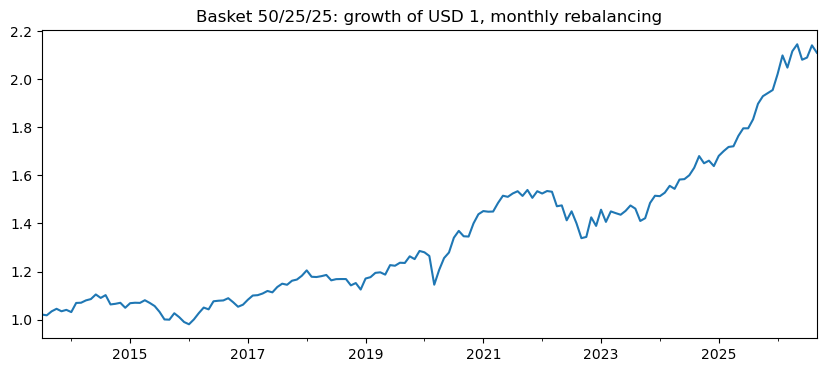

In [19]:
DISCOUNT = 2                     # divide the backtested Sharpe by 2; more with more tuned choices
# Variations tried (Class 4: count the trials and report the count); change the counts here
N_ALLOCATIONS = len(W.columns)   # the allocations of this notebook, each counted once however many tests it goes through
N_EX_ANTE     = 23               # variants compared ex ante on earlier universes (team's count)
N_CHANGES     = 3                # changes of universe or rule: STIP -> TIP, VT -> VTI + VEA + IEMG, 1/sigma -> ERC in the bond basket

# Design, samples and variations
print(f"Design: {n} ETFs + BIL, fixed weights of {SAA}, rebalanced monthly, no transaction costs")
print("Tests: full sample (section 8), hold-out (8b), split (8c)")
print(f"Backtest:          {R.index[0]:%b %Y} - {R.index[-1]:%b %Y} ({len(R)} months)")
print(f"Used for weights:  {est.index[0]:%b %Y} - {est.index[-1]:%b %Y} ({len(est)} months, estimation window)")
print(f"Held out (8b):     {R_out.index[0]:%b %Y} - {R_out.index[-1]:%b %Y} ({len(R_out)} months)")
print(f"Variations: {N_ALLOCATIONS} allocations + {N_EX_ANTE} variants ex ante + {N_CHANGES} changes = "
      f"{N_ALLOCATIONS + N_EX_ANTE + N_CHANGES}")
for g, cols in GROUPS.items():
    print(f"{g}: {', '.join(cols)}")

# Backtested SAA on the estimation window (tuning), on the held-out months (the figures we rely on) and on the full sample
cp3 = {}
for name, r, rf_s in [("Tuning sample", bt[SAA][est.index], rf[est.index]),
                      ("Held out",      bt_out[SAA],         rf_out),
                      ("Full sample",   bt[SAA],             rf)]:
    p = perf(r, rf_s)
    cp3[name] = {"Months":             len(r),
                 "Mean excess return": (r - rf_s).mean() * 12,          # annualized
                 "t-stat":             p["Sharpe"] * np.sqrt(len(r) / 12),   # = mean excess return / (vol / sqrt(T))
                 "Ann. return":        p["Ann. return"],
                 "Cum. return":        p["Cum. return"],
                 "Ann. vol":           p["Ann. vol"],
                 "Max drawdown":       p["Max drawdown"],
                 "VaR 5% 1m":          var_normal(p["Ann. vol"]),
                 "VaR USD":            var_normal(p["Ann. vol"]) * CAPITAL,
                 "Sharpe":             p["Sharpe"],
                 "Sortino":            p["Sortino"],
                 "Discounted Sharpe":  p["Sharpe"] / DISCOUNT}
cp3 = pd.DataFrame(cp3)
se_sharpe = cp3.loc["Sharpe", "Held out"] / cp3.loc["t-stat", "Held out"]          # standard error of the hold-out Sharpe
print(f"Standard error of the hold-out Sharpe: {se_sharpe:.2f} (Sharpe / t-stat)")
display(show(cp3, special={"Months": USD, "VaR USD": USD, "Sharpe": DEC, "Sortino": DEC,
                           "t-stat": DEC, "Discounted Sharpe": DEC}))

# Cumulative return of our SAA over the full sample
(1 + bt[SAA]).cumprod().plot(figsize=(10, 4), title=f"{SAA}: growth of USD 1, monthly rebalancing")
plt.show()

## 9. From weights to the Bloomberg portfolio
Number of shares of each ETF, with $W_0$ = USD 100 million and $P_i$ the **raw close of Friday 16 October 2026** from `AMC_closing_raw.csv` (BCI US Equity included), the price Bloomberg uses for the positions entered on 17–18 October.
1. **Bonds and commodities first**: $N_i = \lfloor w_i W_0 / P_i \rfloor$, whole shares rounded down, so these positions keep their target weights up to one share
2. **Equity last**: the capital left, $C = W_0 - \sum_{j \in \text{bonds, commodities}} N_j P_j$, is split among VTI, VEA and IEMG in proportion to their capital weights, $N_i = \lfloor C \, w_i / \sum_{k \in \text{equity}} w_k \, / \, P_i \rfloor$. $C$ contains the 0.01% that the optimizer leaves unallocated and the rounding leftovers of step 1, so they are invested in equity, the growth engine of our risk budget, instead of staying idle
3. **Last leftover**: what step 2 leaves (less than one share of each equity ETF) buys whole shares of the cheapest equity ETF, VEA at the closes of 16 October: 2 more shares, so that less than one VEA share stays in cash

- **BIL gets no shares.** BIL is used only when the risk budgets give an ex-ante volatility above the 9% cap; our SAA is inside the 7–9% band (7a). The 0.01% left by the optimizer is a numerical residual (risk budgets fix the shares of risk, not the scale of the weights), not a cash leg
- A position below 2% of the capital would get no shares and its weight would go to equity with the rest (the rule does not bind: the smallest weight is printed below)
- The final leftover cash is less than one share of VEA and earns 0

Below: the actual weights against the target weights and the risk of the portfolio we buy, then the portfolio description of the report (name, Bloomberg ticker, currency, shares, price, price date, weights), saved as `portfolio_for_PRTU.csv` with the 8 positions to enter in PRTU.

In [20]:
# 1. Prices: raw closes of Friday 16 October 2026, the prices Bloomberg uses for the positions entered on 17-18 October
closes = pd.read_csv(CLOSE_FILE, index_col=0, encoding="utf-8-sig")         # one row, Bloomberg tickers as columns
closes.index = pd.to_datetime(closes.index, format="%d.%m.%Y")
PRICE_DATE = closes.index[-1]
assert PRICE_DATE == pd.Timestamp("2026-10-16") and PRICE_DATE.dayofweek == 4, "we need the closes of Friday 16 October 2026"
px = closes.iloc[-1].rename({bbg: t for t, bbg in BBG_TRADE.items()})        # Bloomberg ticker -> our ticker (BCI US EQUITY -> BCOMTR)
assert px[ASSETS].notna().all(), "AMC_closing_raw.csv must contain the 8 ETFs"
# BCOMTR is an index: we hold BCI US Equity, the ETF that tracks it (BCOMTR stays the return proxy in sections 2-8)
BCI_CLOSE = px["BCOMTR"]                                                     # raw close of BCI US Equity on PRICE_DATE
assert BCI_CLOSE > 0, "missing close of BCI US Equity"

# 2. Target weights of the 8 ETFs; a position below 2% gets no shares and its weight goes to equity in step 4
w = W[SAA].copy()
print(f"Smallest weight: {w.idxmin()} {w.min():.2%} (a position below 2% gets no shares)")
w[w < 0.02] = 0
# BIL gets no shares: our ex-ante vol is inside the 7-9% band, so the 9% cap does not bind. The 0.01% that the
# optimizer leaves unallocated (risk budgets fix the shares of risk, not the scale) goes to equity in step 4

# 3. Bonds and commodities first: whole shares, rounded down
FIRST, EQUITY = BASKETS["Bonds"] + BASKETS["Commodities"], BASKETS["Equity"]
first = np.floor(w[FIRST] * CAPITAL / px[FIRST])

# 4. Equity last: the capital left (the 0.01% of BIL + the rounding leftovers of step 3), in proportion to the equity weights
remaining = CAPITAL - (first * px[FIRST]).sum()
equity = np.floor(remaining * w[EQUITY] / w[EQUITY].sum() / px[EQUITY])

shares = pd.concat([equity, first])[ASSETS].astype(int)      # back in the order of ASSETS

# 5. Last leftover: whole shares of the cheapest equity ETF (VEA at the closes of 16 October: 2 more shares)
TOP_UP = px[EQUITY].idxmin()
left = CAPITAL - (shares * px[ASSETS]).sum()                 # less than one share of each equity ETF
extra = int(left // px[TOP_UP])
shares[TOP_UP] += extra

value = shares * px[ASSETS]                                  # USD invested in each ETF
cash = CAPITAL - value.sum()                                 # final leftover: less than one share of TOP_UP, earns 0
w_actual = value / CAPITAL                                   # actual weights after rounding
assert value.sum() <= CAPITAL and cash < px[TOP_UP]

# 6. Risk of the portfolio we actually buy (the cash has no risk)
vol_actual = port_vol(w_actual, V.values)
assert VOL_MIN <= vol_actual <= VOL_MAX, "the portfolio we buy must stay in the 7-9% band"
print(f"{SAA}, raw closes of {PRICE_DATE:%A %d %B %Y}")
print(f"Leftover after step 4: USD {left:,.2f}, buys {extra} more shares of {TOP_UP} (USD {extra * px[TOP_UP]:,.2f})")
print(f"Invested: USD {value.sum():,.2f} | leftover cash: USD {cash:,.2f} ({cash / CAPITAL:.4%}, earns 0)")
print(f"Equity: {w_actual[EQUITY].sum():.2%} of the capital (target {W[SAA][EQUITY].sum():.2%})")
print(f"Ex-ante vol {vol_actual:.2%} | 1-month 5% VaR {var_normal(vol_actual):.2%} = USD {var_normal(vol_actual) * CAPITAL:,.0f}")
display(show(pd.DataFrame({"Target weight":   W[SAA],
                           "Actual weight":   w_actual,
                           "Difference (pp)": (w_actual - W[SAA]) * 100,
                           "%RC":             risk_contrib(w_actual, V.values)}),
             special={"Difference (pp)": "{:+.4f}"}, axis=1))

# 7. Portfolio description (report) and input for PRTU, saved next to the notebook
report = pd.DataFrame({"Name":             [NAMES[t] for t in ASSETS],
                       "Bloomberg ticker": [BBG_TRADE[t].replace("EQUITY", "Equity") for t in ASSETS],   # tickers to enter in PRTU
                       "Currency":         "USD",
                       "Shares":           shares,
                       "Close price":      px[ASSETS],
                       "Price date":       f"{PRICE_DATE:%d %b %Y}",
                       "Target weight":    W[SAA],
                       "Actual weight":    w_actual,
                       "USD invested":     value}, index=ASSETS)
prtu = report[["Name", "Bloomberg ticker", "Currency", "Shares", "Close price", "Price date"]].assign(Weight=w_actual.round(6))
assert len(prtu) == 8 and (prtu["Shares"] > 0).all(), "PRTU needs the 8 ETFs, each with its shares"
assert prtu["Bloomberg ticker"].str.endswith(" US Equity").all() and "BCI US Equity" in set(prtu["Bloomberg ticker"])
assert not prtu["Bloomberg ticker"].str.contains("INDEX|BIL", case=False).any(), "no index and no BIL in PRTU"
prtu.to_csv("portfolio_for_PRTU.csv", index=False)

report.loc["Cash"] = ["Cash, rounding leftover", "", "USD", np.nan, np.nan, "", np.nan, cash / CAPITAL, cash]
show(report, special={"Shares": USD, "Close price": "{:,.2f}", "USD invested": "{:,.2f}"}, axis=1)

Smallest weight: IEMG 10.23% (a position below 2% gets no shares)
Basket 50/25/25, raw closes of Friday 16 October 2026
Leftover after step 4: USD 144.20, buys 2 more shares of VEA (USD 138.98)
Invested: USD 99,999,994.78 | leftover cash: USD 5.22 (0.0000%, earns 0)
Equity: 31.38% of the capital (target 31.37%)
Ex-ante vol 8.13% | 1-month 5% VaR 3.86% = USD 3,861,174


,Target weight,Actual weight,Difference (pp),%RC
VTI,10.90%,10.90%,+0.0040,15.21%
VEA,10.24%,10.24%,+0.0039,17.42%
IEMG,10.23%,10.24%,+0.0037,17.37%
BND,13.33%,13.33%,-0.0001,8.33%
BNDX,16.48%,16.48%,+0.0000,7.82%
TIP,15.26%,15.26%,-0.0001,8.84%
GLD,11.15%,11.15%,+0.0000,15.49%
BCOMTR,12.40%,12.40%,+0.0000,9.51%


,Name,Bloomberg ticker,Currency,Shares,Close price,Price date,Target weight,Actual weight,USD invested
VTI,Vanguard Total Stock Market ETF,VTI US Equity,USD,"29,149",374.07,16 Oct 2026,10.90%,10.90%,"10,903,766.43"
VEA,Vanguard FTSE Developed Markets ETF,VEA US Equity,USD,"147,369",69.49,16 Oct 2026,10.24%,10.24%,"10,240,671.81"
IEMG,iShares Core MSCI Emerging Markets ETF,IEMG US Equity,USD,"133,320",76.79,16 Oct 2026,10.23%,10.24%,"10,237,642.80"
BND,Vanguard Total Bond Market ETF,BND US Equity,USD,"188,225",70.82,16 Oct 2026,13.33%,13.33%,"13,330,094.50"
BNDX,Vanguard Total International Bond ETF,BNDX US Equity,USD,"349,731",47.13,16 Oct 2026,16.48%,16.48%,"16,482,822.03"
TIP,iShares TIPS Bond ETF,TIP US Equity,USD,"144,602",105.54,16 Oct 2026,15.26%,15.26%,"15,261,295.08"
GLD,SPDR Gold Shares,GLD US Equity,USD,"29,177",382.01,16 Oct 2026,11.15%,11.15%,"11,145,905.77"
BCOMTR,abrdn Bloomberg All Commodity Strategy K-1 Free ETF,BCI US Equity,USD,"469,258",26.42,16 Oct 2026,12.40%,12.40%,"12,397,796.36"
Cash,"Cash, rounding leftover",,USD,,,,,0.00%,5.22


### In Bloomberg
- `PRTU` → *Create* → **Equity**, **Shares/Par amount**, USD
- Enter the **8 ETFs** of `portfolio_for_PRTU.csv`, each Bloomberg ticker with its **number of shares**, on **Saturday 17 or Sunday 18 October**, so that Bloomberg uses the close of Friday 16 October. No BIL; the leftover cash of section 9 is not entered
- *Action* → *Update Corporate Actions* → tick **adjust cash for coupon payments and dividends** and **reinvest cash dividends**
- **Share** the portfolio with the TA · monitor it with `PORT`

## 10. Figures of the report
The numbers of the report that sections 1–9 do not compute, one cell per element of the report, then the export of **every number of the report** to `report_figures.json`, formatted as the report prints it. The report takes its numbers from this file only, so the notebook is their single source. Not computed here: section 01 of the report (market outlook) and the facts cited from fact sheets and data providers.

In [21]:
# Formats of the report: d decimals, U+2212 for negative numbers, never "-0.00"
def num(x, d=2):
    s = f"{x:.{d}f}"
    return (s.lstrip("-") if float(s) == 0 else s).replace("-", "\u2212")

def pct(x, d=2):                       # 0.0739 -> "7.39%"
    return num(x * 100, d) + "%"

def signed(x, d=1):                    # 0.157 -> "+15.7%"
    return ("+" if round(x * 100, d) > 0 else "") + pct(x, d)

def usd(x, d=0):                       # 3860465 -> "3,860,465"
    return f"{x:,.{d}f}"

def span(a, b, f="%b %Y"):             # "Oct 2021 – Sep 2026"
    return f"{a:{f}} – {b:{f}}"

def between(lo, hi, d=2, unit=""):     # "0.72–0.82"
    return f"{num(lo, d)}–{num(hi, d)}{unit}"

ETF = {t: "BCI" if t == "BCOMTR" else t for t in ASSETS}             # names of the ETFs in the report
NAME = {"Basket 1/3": "Basket 33/33/33", "Basket 50/25/25": "Basket 50/25/25", "Basket 60/20/20": "Basket 60/20/20",
        "Basket 70/15/15": "Basket 70/15/15", "EW": "Equal weight", "RP 1/vol": "Risk parity 1/σ", "Min var": "Minimum variance",
        "Max Sharpe": "Maximum Sharpe", "RP (ERC)": "ERC, 8 ETFs", "MVO @ 8%": "Mean–variance at 8%", "MDP": "Max. diversification"}
CP2_NAME = dict(zip(CP2, ["Our SAA", "Equal weight", "Risk parity 1/σ"]))
EQ, BD, CM = BASKETS["Equity"], BASKETS["Bonds"], BASKETS["Commodities"]
exante = summary.loc["Ex-ante vol"]                                  # ex-ante volatility of each allocation (7a)
FIGURES = {"text": {}}                                               # filled below, written to report_figures.json at the end

### Table 9 · Calendar-year returns
Total return of each calendar year of our SAA, equal weight and risk parity 1/vol (full-sample backtest, section 8). The sample starts in July 2013, so the table starts in 2014; the last year runs from January to September 2026.

In [22]:
calendar = (1 + bt[CP2]).groupby(bt.index.year).prod() - 1           # compounded monthly returns of each year
table9 = calendar.loc[2014:].T                                        # 2013 starts in July: not a full year
FIGURES["table9"] = {CP2_NAME[c]: {(f"{y}*" if y == R.index[-1].year else str(y)): num(table9.loc[c, y] * 100, 1)
                                   for y in table9.columns} for c in CP2}
show(table9, "{:.1%}")

,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Basket 50/25/25,0.8%,-5.7%,7.3%,11.3%,-4.8%,14.3%,11.9%,6.7%,-9.4%,9.0%,8.2%,19.3%,7.9%
EW,0.3%,-6.1%,7.6%,13.1%,-5.7%,15.3%,12.7%,7.3%,-9.6%,9.8%,8.9%,21.6%,9.1%
RP 1/vol,2.5%,-3.8%,6.3%,9.1%,-3.4%,12.7%,10.9%,4.7%,-10.6%,8.4%,6.3%,15.0%,5.1%


### Figure 2 · Growth of USD 1
USD 1 invested at the end of June 2013 in our SAA, equal weight and risk parity 1/vol, rebalanced monthly (section 8). The shaded band is the estimation window of the weights.

End value of USD 1: {'Our SAA': '2.11', 'Equal weight': '2.27', 'Risk parity 1/σ': '1.86'}


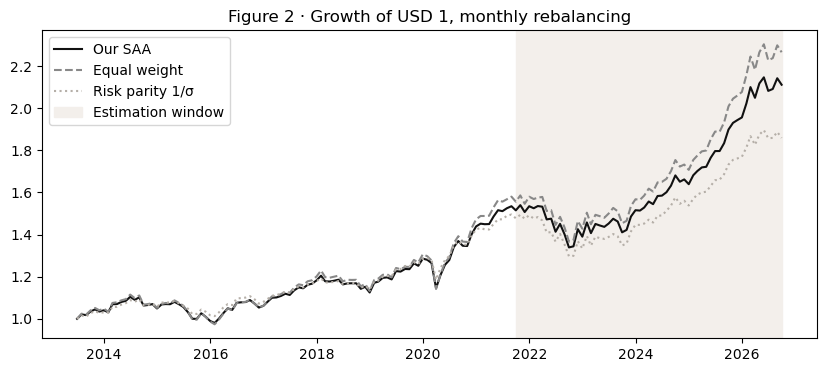

In [23]:
growth = (1 + bt[CP2]).cumprod()
growth.loc[R.index[0] - pd.offsets.MonthEnd(1)] = 1.0                 # USD 1 at the end of June 2013
growth = growth.sort_index()
FIGURES["figure2"] = {"start": f"{growth.index[0]:%b %Y}",
                      "estimation_window": span(est.index[0], est.index[-1]),
                      "end_values": {CP2_NAME[c]: num(growth[c].iloc[-1]) for c in CP2},
                      "series": {"dates": [f"{d:%Y-%m-%d}" for d in growth.index],
                                 **{CP2_NAME[c]: growth[c].round(6).tolist() for c in CP2}}}
print("End value of USD 1:", FIGURES["figure2"]["end_values"])
fig, ax = plt.subplots(figsize=(10, 4))
for c, color, style in zip(CP2, ["#111111", "#888888", "#b5afa8"], ["-", "--", ":"]):
    ax.plot(growth.index, growth[c], style, color=color, label=CP2_NAME[c])
ax.axvspan(est.index[0] - pd.offsets.MonthEnd(1), est.index[-1], color="#f3efeb", label="Estimation window")
ax.set_title("Figure 2 · Growth of USD 1, monthly rebalancing")
ax.legend()
plt.show()

### Section 7.2 · Reading the results
The numbers quoted in the text of the backtest (7.2, and the worst month in 6.3): worst month, maximum drawdown with its peak, trough and recovery, March 2020, the return of each ETF in 2022 and in March 2020, the losing calendar years, the realized volatility of our weights in the two samples and the range of the t-statistics of Table 8.

In [24]:
saa = bt[SAA]
wealth = (1 + saa).cumprod()
drawdown = wealth / wealth.cummax() - 1
dd_trough = drawdown.idxmin()
dd_peak = wealth[:dd_trough].idxmax()
dd_recovery = wealth[dd_trough:][wealth[dd_trough:] >= wealth[dd_peak]].index[0]       # first month back at the peak
covid = pd.Timestamp("2020-03-31")
covid_peak = wealth[:covid].idxmax()
covid_recovery = wealth[covid:][wealth[covid:] >= wealth[covid_peak]].index[0]
full_years = calendar.loc[2014:R.index[-1].year - 1, SAA]                            # complete calendar years only
losing = full_years[full_years < 0]
stress = pd.DataFrame({"2022": (1 + R.loc["2022"]).prod() - 1, "March 2020": R.loc["2020-03"].iloc[0]})
t_stats = table8.loc["t-stat"]

print(f"Worst month: {saa.idxmin():%B %Y} {saa.min():.2%}")
print(f"Maximum drawdown {drawdown.min():.2%}: peak {dd_peak:%B %Y}, trough {dd_trough:%B %Y}, recovered {dd_recovery:%B %Y}")
print(f"March 2020: {saa[covid]:.2%} in the month, {drawdown[covid]:.2%} from the peak of {covid_peak:%B %Y}, recovered {covid_recovery:%B %Y}")
print(f"Losing calendar years: {len(losing)} of {len(full_years)} ({', '.join(map(str, losing.index))}), worst {losing.min():.1%}")
print(f"Realized volatility of our weights: {cp3.loc['Ann. vol', 'Held out']:.1%} in the hold-out, "
      f"{cp3.loc['Ann. vol', 'Tuning sample']:.1%} in the estimation window")
print(f"t-statistics of Table 8: {t_stats.min():.2f} to {t_stats.max():.2f}")

FIGURES["text"]["07 Backtest"] = {
    "growth_end": num(growth[SAA].iloc[-1]),
    "ann_return": pct(table8.loc["Ann. return", "Full sample"], 1),
    "ann_vol": pct(table8.loc["Ann. vol", "Full sample"], 1),
    "sharpe": num(table8.loc["Sharpe", "Full sample"]),
    "losing_years": f"{len(losing)} of the {len(full_years)} full calendar years ({', '.join(map(str, losing.index))})",
    "worst_year_loss": pct(-losing.min(), 1),
    "max_dd_loss": pct(-drawdown.min(), 1),
    "max_dd_from_to": f"{dd_peak:%B %Y} to {dd_trough:%B %Y}",
    "max_dd_recovered": f"{dd_recovery:%B %Y}",
    "worst_month": f"{pct(saa.min(), 1)} ({saa.idxmin():%B %Y})",
    "march_2020_month": pct(saa[covid], 1),
    "march_2020_from_peak": pct(drawdown[covid], 1),
    "march_2020_recovered": f"{covid_recovery:%B %Y}",
    "us_equity_2022_fall": pct(-stress.loc["VTI", "2022"], 0),
    "us_bonds_2022_fall": pct(-stress.loc["BND", "2022"], 1),
    "commodities_2022": signed(stress.loc["BCOMTR", "2022"]),
    "gold_2022": signed(stress.loc["GLD", "2022"]),
    "gained_in_2022": ", ".join(ETF[t] for t in stress.index[stress["2022"] > 0]),
    "equities_march_2020_fall": between(-stress.loc[EQ, "March 2020"].max() * 100, -stress.loc[EQ, "March 2020"].min() * 100, 1, "%"),
    "commodities_march_2020_fall": pct(-stress.loc["BCOMTR", "March 2020"], 0),
    "vol_hold_out": pct(cp3.loc["Ann. vol", "Held out"], 1),
    "vol_estimation_window": pct(cp3.loc["Ann. vol", "Tuning sample"], 1),
    "t_stat_range": between(t_stats.min(), t_stats.max(), 1)}
show(stress, "{:.1%}")

Worst month: March 2020 -9.45%
Maximum drawdown -13.04%: peak October 2021, trough September 2022, recovered March 2024
March 2020: -9.45% in the month, -10.92% from the peak of December 2019, recovered July 2020
Losing calendar years: 3 of 12 (2015, 2018, 2022), worst -9.4%
Realized volatility of our weights: 6.9% in the hold-out, 8.1% in the estimation window
t-statistics of Table 8: 1.91 to 2.00


,2022,March 2020
VTI,-20.0%,-21.1%
VEA,-15.9%,-20.0%
IEMG,-20.4%,-21.7%
BND,-12.5%,-0.9%
BNDX,-12.5%,-3.0%
TIP,-11.8%,-1.4%
GLD,0.8%,0.2%
BCOMTR,15.7%,-16.8%


### Section 04 · Correlations and estimation error
The correlation ranges quoted in 4.1, and the standard error of a mean estimated on five years of data, quoted in 4.2 and in Checkpoint 1.

In [25]:
def corr_range(a, b):
    """Lowest and highest correlation between the ETFs of a and those of b (pairs of two different ETFs)."""
    pairs = [corr.loc[i, j] for i in a for j in b if i != j]
    return min(pairs), max(pairs)

ranges = pd.DataFrame({"Equity with equity":     corr_range(EQ, EQ),
                       "Bonds with bonds":       corr_range(BD, BD),
                       "Equity with bonds":      corr_range(EQ, BD),
                       "GLD, BCOMTR with all":   corr_range(CM, ASSETS),
                       "BCOMTR with bonds":      corr_range(["BCOMTR"], BD)}, index=["Lowest", "Highest"]).T
se_mean = 0.15 / np.sqrt(WINDOW / 12)        # standard error of the annual mean of a 15%-volatility ETF, five years of data
print(f"Standard error of the mean of a 15%-volatility ETF over {WINDOW // 12} years: {se_mean:.1%} (15% / sqrt(5))")

FIGURES["text"]["04 Inputs"] = {
    "equity_corr": between(*ranges.loc["Equity with equity"]),
    "bond_corr": between(*ranges.loc["Bonds with bonds"]),
    "stock_bond_corr": between(*ranges.loc["Equity with bonds"]),
    "real_assets_max_corr": num(ranges.loc["GLD, BCOMTR with all", "Highest"]),
    "commodity_bond_corr": f"{num(ranges.loc['BCOMTR with bonds', 'Lowest'])} to {num(ranges.loc['BCOMTR with bonds', 'Highest'])}",
    "bonds_hist_excess": pct(mu[BD].mean(), 0),
    "gold_hist_excess": signed(mu["GLD"]),
    "se_mean_pp": num(se_mean * 100, 1),
    "optimiser_gold": f"{pct(W.loc['GLD', 'MVO @ 8%'], 1)} (MVO @ 8%), {pct(W.loc['GLD', 'Max Sharpe'], 1)} (Max Sharpe)",
    "tip_bnd_corr": num(corr.loc["TIP", "BND"])}
show(ranges, DEC)

Standard error of the mean of a 15%-volatility ETF over 5 years: 6.7% (15% / sqrt(5))


,Lowest,Highest
Equity with equity,0.72,0.82
Bonds with bonds,0.85,0.90
Equity with bonds,0.47,0.64
"GLD, BCOMTR with all",-0.13,0.47
BCOMTR with bonds,-0.13,0.12


### Sections 05–06 · Numbers quoted in the text
The weights and volatilities quoted in the text of 5.3–5.4 and 6.1–6.3, from 7a, 8b and section 4, and the ratio of equity to bond volatility (6.1: a dollar in equity moves the portfolio about as many times more as its volatility is higher).

In [26]:
vol_ratio = vol[EQ].mean() / vol[BD].mean()                        # average equity volatility / average bond volatility
print(f"Volatility: equity {vol[EQ].min():.1%}-{vol[EQ].max():.1%}, bonds {vol[BD].min():.1%}-{vol[BD].max():.1%}; "
      f"ratio of the averages {vol_ratio:.2f}")

FIGURES["text"]["05 Method"] = {
    "budgets_hold_out_sharpe": between(sr_cand.min(), sr_cand.max()),
    "max_sharpe_mvo_gold": f"{pct(W.loc['GLD', 'MVO @ 8%'], 1)}, {pct(W.loc['GLD', 'Max Sharpe'], 1)}",
    "max_sharpe_mvo_us_equity": f"{pct(W.loc['VTI', 'MVO @ 8%'], 1)}, {pct(W.loc['VTI', 'Max Sharpe'], 1)}",
    "max_sharpe_mvo_bil": between(summary.loc["BIL", "Max Sharpe"] * 100, summary.loc["BIL", "MVO @ 8%"] * 100, 0, "%"),
    "min_var_bil": pct(summary.loc["BIL", "Min var"], 1),
    "mdp_bndx": pct(W.loc["BNDX", "MDP"], 0),
    "mdp_commodities": pct(W.loc["BCOMTR", "MDP"], 0),
    "erc_vol": pct(exante["RP (ERC)"], 1),
    "basket_33_vol": pct(exante["Basket 1/3"], 1)}
FIGURES["text"]["06 Allocation"] = {
    "equity_capital": pct(cp1_baskets.loc["Equity", "Capital"], 0), "equity_risk": pct(cp1_baskets.loc["Equity", "Risk"], 0),
    "bonds_capital": pct(cp1_baskets.loc["Bonds", "Capital"], 0), "bonds_risk": pct(cp1_baskets.loc["Bonds", "Risk"], 0),
    "vol_ratio": num(vol_ratio, 1),
    "equity_vol_range": between(vol[EQ].min() * 100, vol[EQ].max() * 100, 0, "%"),
    "bond_vol_range": between(vol[BD].min() * 100, vol[BD].max() * 100, 0, "%"),
    "iemg_vol": pct(vol["IEMG"], 1), "vea_vol": pct(vol["VEA"], 1),
    "iemg_vti_corr": num(corr.loc["IEMG", "VTI"]), "vea_vti_corr": num(corr.loc["VEA", "VTI"]),
    "bndx_vol": pct(vol["BNDX"], 1),
    "bci_risk": pct(cp1.loc["BCOMTR", "%RC"], 1), "gld_risk": pct(cp1.loc["GLD", "%RC"], 1),
    "var_formula": f"1.645 × {pct(vol_saa)} / √12 = {pct(var_normal(vol_saa))}",
    "var_usd_millions": f"USD {var_normal(vol_saa) * CAPITAL / 1e6:.2f} million",
    "ex_ante_vol_short": pct(vol_saa, 1)}

Volatility: equity 15.2%-16.3%, bonds 5.6%-6.8%; ratio of the averages 2.58


### Section 3.3 · Gold look-through
BCI holds gold too. In 2026 gold is 14.9% of the Bloomberg Commodity Index (target weights announced by Bloomberg on 30 October 2025: precious metals 18.8%, energy 29.4%). The gold of our SAA, looking through BCI, is the weight of GLD plus 14.9% of the weight of BCI (target weights).

In [27]:
GOLD_IN_BCOM = 0.149       # 2026 target weight of gold in the Bloomberg Commodity Index (Bloomberg, 30 October 2025)
gold_overlap = GOLD_IN_BCOM * W.loc["BCOMTR", SAA]                    # gold held through BCI
gold_total = W.loc["GLD", SAA] + gold_overlap
print(f"Gold: GLD {W.loc['GLD', SAA]:.2%} + {GOLD_IN_BCOM:.1%} x BCI {W.loc['BCOMTR', SAA]:.2%} = {gold_total:.1%} of the capital "
      f"(through BCI: {gold_overlap * 100:.1f} pp)")
FIGURES["gold"] = {"gold_in_bcom": pct(GOLD_IN_BCOM, 1), "gld_weight": pct(W.loc["GLD", SAA]), "bci_weight": pct(W.loc["BCOMTR", SAA]),
                   "through_bci_pp": num(gold_overlap * 100, 1), "look_through": pct(gold_total, 1)}

Gold: GLD 11.15% + 14.9% x BCI 12.40% = 13.0% of the capital (through BCI: 1.8 pp)


### Checkpoint 1 · Liquidity
Rule: only ETFs with fund assets above USD 1 billion, and every position can be bought within one day of average trading volume. Fund assets and average daily volume are read on Bloomberg (DES, or `VOLUME_AVG_30D`) and entered below; an ETF without data is marked *to verify on Bloomberg*, never assumed. The team checked the other seven ETFs on Bloomberg on 17 October 2026: all pass both rules. Their figures were not recorded, so they are marked *ok (team check)*.

In [28]:
# Fund assets (USD) and average daily volume (shares) read on Bloomberg; None = not checked yet
LIQUIDITY = {"VTI":    (None, None),
             "VEA":    (None, None),
             "IEMG":   (None, None),
             "BND":    (None, None),
             "BNDX":   (None, None),
             "TIP":    (None, None),
             "GLD":    (None, None),
             "BCOMTR": (3.5e9, 1.5e6)}     # BCI: about USD 3.5 billion, 1.5-1.7 million shares a day (team check): the low end
TEAM_CHECKED = ["VTI", "VEA", "IEMG", "BND", "BNDX", "TIP", "GLD"]   # checked on Bloomberg by the team, 17 Oct 2026: both rules met
liq = pd.DataFrame(LIQUIDITY, index=["Fund assets", "Avg daily volume"]).T.astype(float)
liq["Daily value traded"] = liq["Avg daily volume"] * px[ASSETS]       # USD, at the closes of 16 October
liq["Position"] = value[ASSETS]                                       # USD bought in section 9
liq["Position / daily value"] = liq["Position"] / liq["Daily value traded"]
missing = liq[["Fund assets", "Avg daily volume"]].isna().any(axis=1)
ok = (liq["Fund assets"] > 1e9) & (liq["Position / daily value"] <= 1)
liq["Check"] = np.where(missing, np.where(liq.index.isin(TEAM_CHECKED), "ok (team check)", "to verify on Bloomberg"),
                        np.where(ok, "ok", "FAILS"))
FIGURES["liquidity"] = {ETF[t]: {"status": liq.loc[t, "Check"]} if missing[t] else
                        {"fund_assets_usd_bn": num(liq.loc[t, "Fund assets"] / 1e9, 1),
                         "avg_daily_volume_shares": usd(liq.loc[t, "Avg daily volume"]),
                         "daily_value_traded_usd_m": num(liq.loc[t, "Daily value traded"] / 1e6, 1),
                         "position_usd_m": num(liq.loc[t, "Position"] / 1e6, 1),
                         "position_share_of_daily_value": pct(liq.loc[t, "Position / daily value"], 0),
                         "status": liq.loc[t, "Check"]} for t in ASSETS}
show(liq, special={"Fund assets": USD, "Avg daily volume": USD, "Daily value traded": USD, "Position": USD}, axis=1)

,Fund assets,Avg daily volume,Daily value traded,Position,Position / daily value,Check
VTI,,,,"10,903,766",,ok (team check)
VEA,,,,"10,240,672",,ok (team check)
IEMG,,,,"10,237,643",,ok (team check)
BND,,,,"13,330,094",,ok (team check)
BNDX,,,,"16,482,822",,ok (team check)
TIP,,,,"15,261,295",,ok (team check)
GLD,,,,"11,145,906",,ok (team check)
BCOMTR,"3,500,000,000","1,500,000","39,630,000","12,397,796",31.28%,ok


### Table 4 · Colours of the correlation heatmap
The colours of the heatmap of section 4 (`RdBu_r` from −1, blue, through 0, white, to +1, red), as hex codes for the correlation table of the report, with the text colour that pandas puts on each cell (light text on dark cells). The check compares them with the heatmap of section 4.

In [29]:
import re
from matplotlib import colormaps, colors as mcolors

def text_on(rgba, threshold=0.408):
    """Text colour of background_gradient: light on dark cells (relative luminance below the threshold)."""
    r, g, b = (x / 12.92 if x <= 0.04045 else ((x + 0.055) / 1.055) ** 2.4 for x in rgba[:3])
    return "#f1f1f1" if 0.2126 * r + 0.7152 * g + 0.0722 * b < threshold else "#000000"

rgba = colormaps["RdBu_r"](mcolors.Normalize(-1, 1)(corr.values))      # the scale of section 4: vmin -1, vmax 1
heat_bg = pd.DataFrame([[mcolors.rgb2hex(c) for c in row] for row in rgba], index=ASSETS, columns=ASSETS)
heat_text = pd.DataFrame([[text_on(c) for c in row] for row in rgba], index=ASSETS, columns=ASSETS)
heatmap_html = show(corr, DEC).background_gradient(cmap="RdBu_r", vmin=-1, vmax=1).to_html()
section4 = set(re.findall(r"background-color: (#[0-9a-f]{6});\s*color: (#[0-9a-f]{6});", heatmap_html))
assert section4 == set(zip(heat_bg.values.ravel(), heat_text.values.ravel())), "colours differ from the heatmap of section 4"
FIGURES["heatmap"] = {"scale": "RdBu_r, from -1 (blue) through 0 (white) to +1 (red), as section 4",
                      "background": {ETF[i]: {ETF[j]: heat_bg.loc[i, j] for j in ASSETS} for i in ASSETS},
                      "text": {ETF[i]: {ETF[j]: heat_text.loc[i, j] for j in ASSETS} for i in ASSETS}}
corr.style.format(DEC).apply(lambda _: ("background-color: " + heat_bg + "; color: " + heat_text).values, axis=None)

,VTI,VEA,IEMG,BND,BNDX,TIP,GLD,BCOMTR
VTI,1.00,0.82,0.72,0.50,0.53,0.53,0.14,0.09
VEA,0.82,1.00,0.81,0.64,0.58,0.62,0.42,0.20
IEMG,0.72,0.81,1.00,0.56,0.47,0.53,0.44,0.24
BND,0.50,0.64,0.56,1.00,0.89,0.90,0.46,-0.06
BNDX,0.53,0.58,0.47,0.89,1.00,0.85,0.41,-0.13
TIP,0.53,0.62,0.53,0.90,0.85,1.00,0.47,0.12
GLD,0.14,0.42,0.44,0.46,0.41,0.47,1.00,0.31
BCOMTR,0.09,0.20,0.24,-0.06,-0.13,0.12,0.31,1.00


### Export: `report_figures.json`
Every number of the report, grouped by element of the report and formatted as the report prints it (decimals, % sign, thousands separators, U+2212 for negatives): the cells above, and the tables and figures of sections 4–9 and of the checkpoints. The report prompts copy their numbers from this file.

In [30]:
import json

MARKET_DATE = pd.Timestamp("2026-10-09")    # date of the market data of the report (T-bill quoted in Checkpoint 1 and 3.4)
limit = raw.droplevel(0, axis=1).apply(lambda s: s.first_valid_index())   # first price of each ETF
table8_cols = {"Full sample": ("Full sample", bt[SAA]), "Hold-out": ("Hold-out (8b)", bt_out[SAA]), "Split": ("Split (8c)", bt_first[SAA])}
cp3_cols = {"Tuning sample": "Tuning sample", "Hold-out sample": "Held out", "Full sample": "Full sample"}

FIGURES = {**{
    "about": "Every number of the Round 1 report, written by section 10 of SAA_R1_our_version.ipynb and formatted as the report "
             "prints it. Not here: section 01 (market outlook) and facts cited from fact sheets and data providers.",
    "cover": {"nav": f"USD {CAPITAL / 1e6:.0f}M", "vol_target": f"{VOL_TARGET:.0%} p.a."},
    "samples": {"data": f"{raw.index[0]:%B %Y} – {raw.index[-1]:%d %B %Y}",
                "full": span(R.index[0], R.index[-1]), "full_months": str(len(R)),
                "start_limit": f"{limit.idxmax().split()[0]} ({limit.max():%B %Y})",
                "estimation": span(est.index[0], est.index[-1]), "estimation_months": str(len(est)),
                "hold_out": span(R_out.index[0], R_out.index[-1]), "hold_out_months": str(len(R_out)),
                "split_estimation": span(est_first.index[0], est_first.index[-1]),
                "split_test": span(R_test.index[0], R_test.index[-1]), "split_test_months": str(len(R_test))},
    "cp1": {"vol_target": pct(VOL_TARGET, 0), "vol_range": f"{VOL_MIN:.0%}–{VOL_MAX:.0%}".replace("%–", "–"),
            "ex_ante_vol": pct(vol_saa), "var_1m": pct(var_normal(vol_saa)),
            "var_usd_millions": f"USD {var_normal(vol_saa) * CAPITAL / 1e6:.2f} million",
            "max_dd_acceptable": pct(MAX_DD, 0), "max_dd_backtest": pct(drawdown.min(), 1), "max_dd_year": f"{dd_trough:%Y}",
            "weight": {ETF.get(t, t): pct(cp1.loc[t, "Weight"]) for t in cp1.index},
            "risk": {ETF.get(t, t): pct(cp1.loc[t, "%RC"]) for t in cp1.index},
            "largest_risk": f"{ETF[cp1.loc[ASSETS, '%RC'].idxmax()]}, {pct(cp1.loc[ASSETS, '%RC'].max(), 1)}",
            "above_half_of_risk": "none" if cp1.loc[ASSETS, "%RC"].max() <= 0.5 else ETF[cp1.loc[ASSETS, "%RC"].idxmax()],
            "baskets": {b: {"capital": pct(cp1_baskets.loc[b, "Capital"], 1), "risk": pct(cp1_baskets.loc[b, "Risk"], 1)} for b in BASKETS},
            "largest_etf_capital": f"{ETF[W[SAA].idxmax()]} {pct(W[SAA].max())}",
            "largest_etf_risk": f"{ETF[cp1.loc[ASSETS, '%RC'].idxmax()]} {pct(cp1.loc[ASSETS, '%RC'].max())}",
            "equity_split": " / ".join(f"{x * 100:.0f}" for x in eq / eq.sum()),
            "hist_excess_us": pct(mu["VTI"], 1), "hist_excess_em": pct(mu["IEMG"], 1),
            "se_mean": f"{se_mean * 100:.0f} pp", "optimiser_gold": pct(W.loc["GLD", "Max Sharpe"], 0),
            "tbill": pct(pd.to_numeric(tbill, errors="coerce")[MARKET_DATE] / 100), "tbill_date": f"{MARKET_DATE:%d %b %Y}"},
    "table3": {ETF[t]: {"vol": pct(vol[t]), "excess_return": pct(mu[t])} for t in ASSETS},
    "table4": {ETF[i]: {ETF[j]: "1" if i == j else num(corr.loc[i, j]) for j in ASSETS} for i in ASSETS},
    "table5": {BUDGET: {"ex_ante_vol": pct(exante[c]), "bil": pct(summary.loc["BIL", c]), "sharpe_hold_out": num(sr_cand[c])}
               for c, BUDGET in zip(GROUPS["Candidates"], ["33 / 33 / 33", "50 / 25 / 25", "60 / 20 / 20", "70 / 15 / 15"])},
    "table6": {NAME[c]: {"group": GROUP[c], **{ETF[t]: num(W.loc[t, c] * 100, 1) for t in ASSETS},
                         "BIL": num(summary.loc["BIL", c] * 100, 1), "vol": num(exante[c] * 100)} for c in W},
    "table7": {"kpi": {"ex_ante_vol": pct(vol_saa), "var_1m": pct(var_normal(vol_saa)),
                       "var_usd": f"USD {usd(var_normal(vol_saa) * CAPITAL)}",
                       "positions": f"{n} ETFs", "largest_risk": pct(cp1.loc[ASSETS, "%RC"].max(), 1),
                       "largest_risk_etf": ETF[cp1.loc[ASSETS, "%RC"].idxmax()]},
               "rows": {ETF.get(t, t): {"capital": pct(cp1.loc[t, "Weight"]), "risk": pct(cp1.loc[t, "%RC"])} for t in ASSETS + ["BIL"]},
               "baskets": {b: {"capital": pct(cp1_baskets.loc[b, "Capital"]), "risk": pct(cp1_baskets.loc[b, "Risk"], 1)} for b in BASKETS}},
    "table8": {name: {"period": f"{r.index[0]:%m.%y}–{r.index[-1]:%m.%y}",
                      "ann_return": pct(table8.loc["Ann. return", col]), "cum_return": pct(table8.loc["Cum. return", col], 1),
                      "ann_vol": pct(table8.loc["Ann. vol", col]),
                      "sharpe_tstat": f"{num(table8.loc['Sharpe', col])} ({num(table8.loc['t-stat', col])})",
                      "sortino": num(table8.loc["Sortino", col]), "max_dd": pct(table8.loc["Max drawdown", col]),
                      "var_1m": pct(table8.loc["VaR 5% 1m", col])} for name, (col, r) in table8_cols.items()},
    "table10": {NAME[c]: {"group": GROUP[c],
                          "full_sharpe": num(table10.loc[c, ("Full sample", "Sharpe")]),
                          "full_vol": pct(table10.loc[c, ("Full sample", "Ann. vol")]),
                          "hold_out_sharpe": num(table10.loc[c, ("Hold-out (8b)", "Sharpe")]),
                          "hold_out_vol": pct(table10.loc[c, ("Hold-out (8b)", "Ann. vol")])} for c in W},
    "cp2": {CP2_NAME[c]: {"weight": {ETF.get(t, t): pct(cp2.loc[t, (c, "Weight")]) for t in ASSETS + ["BIL"]},
                          "risk": {ETF.get(t, t): pct(cp2.loc[t, (c, "%RC")]) for t in ASSETS + ["BIL"]},
                          "baskets": {b: {"capital": pct(cp2.loc[b, (c, "Weight")], 1), "risk": pct(cp2.loc[b, (c, "%RC")], 1)}
                                      for b in BASKETS},
                          "vol": pct(cp2.loc["Ex-ante vol", (c, "Weight")])} for c in CP2},
    "cp3": {"design": {"universe": f"{n} ETFs + BIL", "rule": f"Basket method {SAA.split()[-1]}", "window": f"{WINDOW} months",
                       "sample": f"{span(R.index[0], R.index[-1])}, {len(R)} monthly total returns"},
            "validation": {"tuning": f"{span(est.index[0], est.index[-1])} ({len(est)} months)",
                           "hold_out": f"{span(R_out.index[0], R_out.index[-1])} ({len(R_out)} months)",
                           "variations": str(N_ALLOCATIONS + N_EX_ANTE + N_CHANGES), "allocations": str(N_ALLOCATIONS),
                           "designs": "3", "ex_ante": str(N_EX_ANTE), "changes": str(N_CHANGES),
                           **{g.split()[0].lower(): [NAME[c] for c in cols] for g, cols in GROUPS.items()}},
            "risk": {name: {"mean_excess_tstat": f"{pct(cp3.loc['Mean excess return', col])} ({num(cp3.loc['t-stat', col])})",
                            "ann_vol": pct(cp3.loc["Ann. vol", col]), "max_dd": pct(cp3.loc["Max drawdown", col]),
                            "var_1m": pct(cp3.loc["VaR 5% 1m", col]), "var_usd": usd(cp3.loc["VaR USD", col]),
                            "sharpe": num(cp3.loc["Sharpe", col])} for name, col in cp3_cols.items()},
            "discount": {"backtested_sharpe": num(cp3.loc["Sharpe", "Held out"]), "discount": f"÷ {DISCOUNT}",
                         "discounted_sharpe": num(cp3.loc["Discounted Sharpe", "Held out"]),
                         "t_stat": num(cp3.loc["t-stat", "Held out"], 1), "se_sharpe": num(se_sharpe)}},
    "portfolio": {"price_date": f"{PRICE_DATE:%A %d %B %Y}",
                  "rows": {ETF[t]: {"security": NAMES[t], "ticker": report.loc[t, "Bloomberg ticker"], "ccy": "USD",
                                    "shares": usd(shares[t]), "price": num(px[t]), "weight": pct(w_actual[t])} for t in ASSETS},
                  "cash": {"usd": usd(cash, 2), "weight": pct(cash / CAPITAL)},
                  "total": {"usd": usd(CAPITAL), "weight": pct(w_actual.sum() + cash / CAPITAL)},
                  "leftover_before_top_up": usd(left, 2), "top_up": f"{extra} more shares of {TOP_UP}",
                  "max_weight_difference_pp": num((w_actual - W[SAA]).abs().max() * 100, 3),
                  "ex_ante_vol": pct(vol_actual), "var_1m": pct(var_normal(vol_actual)),
                  "var_usd": usd(var_normal(vol_actual) * CAPITAL)}},
    "table9": FIGURES["table9"], "figure2": FIGURES["figure2"], "heatmap": FIGURES["heatmap"],
    "gold": FIGURES["gold"], "liquidity": FIGURES["liquidity"], "text": FIGURES["text"]}
ORDER = ["about", "cover", "samples", "cp1", "table3", "table4", "heatmap", "table5", "table6", "table7", "table8", "table9",
         "figure2", "table10", "cp2", "cp3", "portfolio", "gold", "liquidity", "text"]          # the order of the report
FIGURES = {k: FIGURES[k] for k in ORDER}
FIGURES["text"]["Checkpoint 2"] = {
    "weight_range": between(W[CP2].min().min() * 100, W[CP2].max().max() * 100, 0, "%"),
    "ew_equity": f"{pct(cp2.loc['Equity', ('EW', 'Weight')], 1)} of the capital and {pct(cp2.loc['Equity', ('EW', '%RC')], 0)} of the risk",
    "vol_ratio": num(vol_ratio, 1),
    "rp_equity": f"{pct(cp2.loc['Equity', ('RP 1/vol', 'Weight')], 0)} and {pct(cp2.loc['Equity', ('RP 1/vol', '%RC')], 0)}",
    "saa_equity": f"{pct(cp2.loc['Equity', (SAA, 'Weight')], 0)} of capital and {pct(cp2.loc['Equity', (SAA, '%RC')], 0)} of risk",
    "rp_bonds_capital": pct(cp2.loc["Bonds", ("RP 1/vol", "Weight")], 0),
    "saa_bonds_capital": pct(cp2.loc["Bonds", (SAA, "Weight")], 0),
    "bond_corr": between(*ranges.loc["Bonds with bonds"]),
    "rp_real_assets": f"{pct(cp2.loc['Commodities', ('RP 1/vol', 'Weight')], 0)} of the capital and "
                      f"{pct(cp2.loc['Commodities', ('RP 1/vol', '%RC')], 0)} of the risk",
    "saa_real_assets_risk": pct(cp2.loc["Commodities", (SAA, "%RC")], 0),
    "optimiser_gold": between(W.loc["GLD", "MVO @ 8%"] * 100, W.loc["GLD", "Max Sharpe"] * 100, 0, "%"),
    "hold_out_rp_vs_saa": f"{num(table10.loc['RP 1/vol', ('Hold-out (8b)', 'Sharpe')])} against "
                          f"{num(table10.loc[SAA, ('Hold-out (8b)', 'Sharpe')])}",
    "hold_out_ew": num(table10.loc["EW", ("Hold-out (8b)", "Sharpe")])}

with open("report_figures.json", "w", encoding="utf-8") as fh:
    json.dump(FIGURES, fh, indent=1, ensure_ascii=False)
def leaves(d):
    return sum(leaves(v) for v in d.values()) if isinstance(d, dict) else 1
print(f"report_figures.json: {len(FIGURES)} elements of the report, {leaves(FIGURES)} values")

report_figures.json: 20 elements of the report, 819 values


## Appendix — Walk-forward test (not used in the report)
At the end of every month, `V` and `mu` are estimated on the previous 60 months only, the allocations are rebuilt with the rules of sections 6–7 and held during the next month, as an investor would have done in real time.

**Why the report does not use it:** it re-estimates the weights every month, a dynamic strategy we do not follow: our SAA is estimated once and stays fixed until Round 2. Our SAA is tested by the hold-out (8b) and the split (8c); this test is kept for reference only.
- It tests the method (e.g. "MVO at 8% on 60-month inputs"), not the weights we hold until Round 2
- Fully out-of-sample: the weights of each month only use data available before that month
- Limits: it starts only after the first 60 months (July 2018); it ignores the transaction costs of changing the weights every month; the ETF list was chosen today with hindsight; Min var has no unique solution (every portfolio at exactly 7% volatility is optimal), so its result depends on the starting point of the optimizer
- The loop runs about 2,000 optimizations, which takes several seconds

Walk-forward: Jul 2018 - Sep 2026 (99 months, out-of-sample)


,Ann. return,Cum. return,Ann. vol,Sharpe,Sortino,Max drawdown
Basket 1/3,6.75%,69.15%,8.52%,0.47,0.68,-13.89%
Basket 50/25/25,6.97%,71.83%,8.85%,0.48,0.68,-14.47%
Basket 60/20/20,7.11%,73.47%,9.04%,0.48,0.69,-14.71%
Basket 70/15/15,7.25%,75.30%,9.20%,0.49,0.70,-14.87%
EW,8.37%,92.30%,9.20%,0.61,0.92,-13.84%
RP 1/vol,5.43%,53.76%,6.45%,0.42,0.61,-13.39%
Min var,6.79%,69.85%,8.34%,0.48,0.69,-14.49%
Max Sharpe,9.71%,112.26%,10.55%,0.66,0.98,-15.38%
RP (ERC),6.58%,66.85%,8.47%,0.45,0.65,-13.30%
MVO @ 8%,9.32%,105.06%,10.82%,0.61,0.88,-16.13%


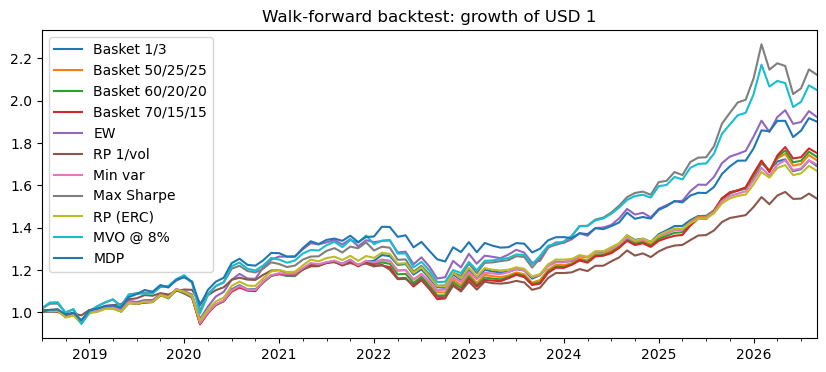

In [31]:
wf = {}
for t in range(WINDOW, len(R)):                               # t = position in R of the month we invest in
    est_t = R.iloc[t - WINDOW:t]                              # the 60 months before month t
    V_t   = (est_t.cov() * 12).values
    mu_t  = (est_t.sub(rf.iloc[t - WINDOW:t], axis=0).mean() * 12).values
    w_t   = allocations(V_t, mu_t, est_t)                     # weights chosen at the end of month t-1
    wf[R.index[t]] = {c: R.iloc[t].values @ w_t[c] + (1 - w_t[c].sum()) * R_bil.iloc[t]
                      for c in w_t}                           # return of month t, rest in BIL

bt_wf = pd.DataFrame.from_dict(wf, orient="index")[W.columns]   # one row per month, one column per allocation
rf_wf = rf.iloc[WINDOW:]
print(f"Walk-forward: {bt_wf.index[0]:%b %Y} - {bt_wf.index[-1]:%b %Y} ({len(bt_wf)} months, out-of-sample)")
display(perf_table(bt_wf, rf_wf))

(1 + bt_wf).cumprod().plot(figsize=(10, 4), title="Walk-forward backtest: growth of USD 1")
plt.show()